# Identificación de cuerpos de agua con Landsat

**Laboratorio N°1 – Procesamiento de Imágenes Multiespectrales con Landsat 8** · Fundamentos del Procesamiento Digital de Imágenes · Grupo N°4
Actividad 2 desarrollada por Brian Aranda.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/lab1/code/ejercicio_2/cuerpos_de_agua.ipynb)

**Consigna (actividad 2).** Resaltar cuerpos de agua (ríos, arroyos, lagos): detectar y analizar su presencia y extensión en la región. Bandas de interés: 2 (azul), 5 (NIR) y 7 (SWIR 2). Se arma una composición RGB que represente el objetivo, se justifica la selección de bandas, se aplica mejora de contraste si hace falta y se analiza si la resolución espacial alcanza.

**Además de la consigna:** se mide la detección con índices de agua y umbralización, se comparan cuerpos de agua grandes y chicos, y se comparan las dos fechas disponibles.

**Escenas** (carpeta de Drive de la cátedra, órbita 224/079, reflectancia de superficie de nivel 2):

| Fecha | Satélite | Nubes | Elevación solar |
|---|---|---|---|
| 03/04/2024 | Landsat 9 (OLI-2) | 0,00 % | 44,8° |
| 30/06/2024 | Landsat 8 (OLI) | 0,02 % | 30,6° |

**Zonas de estudio** (cuadrados de 20 km de lado):

| Zona | Qué aporta |
|---|---|
| A. Paraná entre Posadas y Encarnación | Agua grande, regulada por la represa de Yacyretá: su área debería mantenerse entre fechas |
| B. Río Uruguay y arroyos Chimiray, Tunas y Concepción | Agua grande sin regular y tres arroyos afluentes en la misma imagen. El Chimiray es el límite entre Misiones y Corrientes |
| C. Arroyos cerca de Garuhapé | Arroyos afluentes del Paraná en valles con monte |

En la sección 8 se agregan dos zonas para analizar cambios entre fechas: **D**, lagunas y represas de San Carlos (Corrientes), y **E**, la bahía del arroyo Garupá en el embalse de Yacyretá.

## 1. Configuración y funciones auxiliares

### Ejecución en Google Colab

Colab abre solo este archivo, sin el resto del repositorio. Si el notebook se ejecuta en Colab, la celda siguiente clona el repositorio y se ubica en la carpeta `code/ejercicio_2/`. En una ejecución local no hace nada. Las escenas no están en el repositorio (pesan unos 600 MB cada una): si faltan, la función `preparar_escena` las descarga de la carpeta de Drive de la cátedra.

In [1]:
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    RAMA = "lab1"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_2")
    print("Trabajando en", os.getcwd())

### Librerías, carpetas y datos

In [2]:
# --- Librerías ---
import math
import zipfile
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import color
from skimage.filters import threshold_otsu

# OpenCV avisa por cada etiqueta GeoTIFF que no reconoce (las coordenadas); no afectan la lectura
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

# --- Carpetas ---
DIR_DATOS = Path("datos")              # escenas Landsat: no se suben al repositorio (.gitignore)
DIR_FIG = Path("../../img/ejercicio2")    # figuras del informe
DIR_FIG.mkdir(parents=True, exist_ok=True)

# Exportar las figuras del informe a DIR_FIG. Queda apagado para que ejecutar el
# notebook no modifique los PDFs del repositorio: activarlo solo para regenerarlas.
EXPORTAR_FIGURAS = False
FORMATO_FIGURAS = "pdf"   # "png" para revisar tamaños; "pdf" para el informe

# Figuras que usa el informe: solo estas se exportan.
# Para exportar otra, agregar su nombre a este conjunto.
FIGURAS_INFORME = {"zonas_ubicacion", "bandas_zonas", "indices_zonas", "discrepancias_qa",
                   "arroyos_zona_b", "cambios_fechas",
                   "separabilidad_fisher", "composiciones_seleccionadas"}

# --- Escenas de la carpeta de Drive de la cátedra (nombre del zip: ID del archivo) ---
ESCENAS_DRIVE = {
    "Sur_Misiones_20240403": "1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT",
    "Sur_Misiones_20240630": "1ZSfToE3qhYerY87XmTKS1rGCtgBrDUyq",
}


def preparar_escena(nombre):
    # Devuelve la carpeta de la escena. Si falta, descomprime el zip; si falta el zip, lo descarga.
    carpeta = DIR_DATOS / nombre
    if carpeta.is_dir():
        return carpeta
    DIR_DATOS.mkdir(exist_ok=True)
    archivo = DIR_DATOS / f"{nombre}.zip"
    if not archivo.exists():
        import gdown   # viene instalado en Colab; en local: pip install gdown
        gdown.download(f"https://drive.google.com/uc?id={ESCENAS_DRIVE[nombre]}", str(archivo), quiet=False)
    with zipfile.ZipFile(archivo) as z:
        z.extractall(DIR_DATOS)
    return carpeta

### Figuras con la tipografía del informe

In [3]:
from matplotlib.transforms import Bbox

# Las figuras que se ven en el notebook se guardan en JPEG para que el archivo pese menos;
# las del informe se exportan aparte en PDF con guardar()
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

# Ancho de texto del informe: \the\linewidth = 483.69687 pt (1 in = 72.27 pt en TeX).
# Es el de una figura fuera de listas; dentro de un itemize el ancho es menor.
ANCHO = 483.69687 / 72.27   # ≈ 6.693 in


def ancho(fraccion=1.0):
    # Ancho (in) de una figura que en el informe ocupará `fraccion` del \linewidth.
    # Se inserta sin escalar: \includegraphics{...} (o width=<fraccion>\linewidth),
    # así la letra queda en el mismo tamaño en todas las figuras.
    return fraccion * ANCHO

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "grid.alpha": 0.4,

    # Tamaños de fuente
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,

    # Dimensiones de la figura: el ancho es el del texto del informe
    "figure.figsize": (ANCHO, 4),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.format": "pdf",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,

    # Disposición automática de los paneles, con poco espacio entre ellos
    "figure.constrained_layout.use": True,
    "figure.constrained_layout.w_pad": 0.02,
    "figure.constrained_layout.h_pad": 0.02,
    "figure.constrained_layout.wspace": 0.02,
    "figure.constrained_layout.hspace": 0.02,
})


def guardar(fig, nombre, margen=0.02):
    # Exporta a ../../img/ejercicio2/<nombre>.pdf sin títulos, ni de los paneles ni general
    # (el título va en el caption de LaTeX).
    # El ancho queda exacto: en LaTeX se inserta sin escalar. Solo se recorta el espacio
    # en blanco de arriba y de abajo.
    if not EXPORTAR_FIGURAS or nombre not in FIGURAS_INFORME:
        return
    titulos = [ax.get_title() for ax in fig.axes]
    titulo_general = fig.get_suptitle()
    for ax in fig.axes:
        ax.set_title("")
    fig.suptitle("")
    fig.canvas.draw()
    contenido = fig.get_tightbbox(fig.canvas.get_renderer())   # en pulgadas
    caja = Bbox.from_extents(0, contenido.y0 - margen, fig.get_figwidth(), contenido.y1 + margen)
    # Sin fecha de creación: si la figura no cambió, el PDF es idéntico y git no lo marca
    fig.savefig(DIR_FIG / f"{nombre}.{FORMATO_FIGURAS}", bbox_inches=caja,
                metadata={"CreationDate": None} if FORMATO_FIGURAS == "pdf" else None)
    for ax, titulo in zip(fig.axes, titulos):
        ax.set_title(titulo)
    fig.suptitle(titulo_general)


def mostrar_img(ax, img, titulo="", letra="", **kwargs):
    # Imagen sin ejes, con el rótulo "(a) Título" debajo (se exporta con la figura)
    ax.imshow(img, **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"({letra}) {titulo}" if letra else titulo)


def etiquetar(ax, letra, titulo=""):
    # Rótulo "(a) Título" arriba a la izquierda, dentro de un gráfico con ejes
    texto = f"({letra}) {titulo}" if titulo else f"({letra})"
    ax.text(0.03, 0.95, texto, transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))


def estirar(img, limites):
    # Estiramiento lineal entre dos límites, recortando afuera (normalización de la cátedra)
    lo, hi = limites
    return np.clip((img - lo) / (hi - lo), 0, 1)

### Lectura de las escenas

Cada escena trae las bandas SR_B1 a SR_B7 en enteros de 16 bits, la banda de calidad `QA_PIXEL` y el archivo de metadatos (MTL). El MTL está dividido en secciones, y algunas claves se repiten: por ejemplo, los factores de reflectancia aparecen en la sección de nivel 2 y en la de nivel 1, con valores distintos. Por eso se leen agrupados por sección.

- **Reflectancia de superficie:** $\rho = DN \cdot 2{,}75 \times 10^{-5} - 0{,}2$, con los factores leídos del MTL. $DN = 0$ es relleno (fuera de la huella del satélite) y queda como `NaN`.
- **`QA_PIXEL`:** bit 0 relleno; bits 1 a 3 nube dilatada, cirros y nube; bit 4 sombra de nube; bit 7 agua. El bit de agua lo calcula el USGS con su propio algoritmo: se usa como referencia para comparar, no como verdad de campo.
- **Memoria:** cada banda completa ocupa unos 120 MB. Se lee una banda por vez, se guardan solo los recortes de las zonas y se libera.

In [4]:
NOMBRES_BANDAS = {1: "Costera", 2: "Azul", 3: "Verde", 4: "Rojo", 5: "NIR", 6: "SWIR 1", 7: "SWIR 2"}


def leer_mtl(carpeta):
    # Metadatos agrupados por sección (GROUP = ...)
    mtl, grupo = {}, None
    for linea in next(carpeta.glob("*_MTL.txt")).read_text().splitlines():
        if "=" not in linea:
            continue
        clave, valor = (s.strip() for s in linea.split("=", 1))
        if clave == "GROUP":
            grupo = valor
            mtl[grupo] = {}
        elif clave != "END_GROUP":
            mtl[grupo][clave] = valor.strip('"')
    return mtl


def abrir_escena(nombre):
    carpeta = preparar_escena(nombre)
    mtl = leer_mtl(carpeta)
    imagen, proy = mtl["IMAGE_ATTRIBUTES"], mtl["PROJECTION_ATTRIBUTES"]
    sr = mtl["LEVEL2_SURFACE_REFLECTANCE_PARAMETERS"]
    return {
        "nombre": nombre,
        "carpeta": carpeta,
        "prefijo": next(carpeta.glob("*_MTL.txt")).name.removesuffix("_MTL.txt"),
        "satelite": imagen["SPACECRAFT_ID"].replace("_", " ").title(),
        "fecha": pd.Timestamp(imagen["DATE_ACQUIRED"]),
        "hora_utc": imagen["SCENE_CENTER_TIME"][:8],
        "nubes": float(imagen["CLOUD_COVER"]),
        "elevacion": float(imagen["SUN_ELEVATION"]),
        "azimut": float(imagen["SUN_AZIMUTH"]),
        # Coordenadas UTM (huso 21) del centro del píxel (0, 0): las bandas están
        # georreferenciadas como PixelIsPoint (GTRasterTypeGeoKey = 2)
        "x0": float(proy["CORNER_UL_PROJECTION_X_PRODUCT"]),
        "y0": float(proy["CORNER_UL_PROJECTION_Y_PRODUCT"]),
        "celda": float(proy["GRID_CELL_SIZE_REFLECTIVE"]),
        "mult": {b: float(sr[f"REFLECTANCE_MULT_BAND_{b}"]) for b in NOMBRES_BANDAS},
        "suma": {b: float(sr[f"REFLECTANCE_ADD_BAND_{b}"]) for b in NOMBRES_BANDAS},
    }


def leer_tif(escena, sufijo):
    # cv2.imread no abre rutas con tildes en Windows: se lee el archivo como bytes y se decodifica
    ruta = escena["carpeta"] / f"{escena['prefijo']}_{sufijo}.TIF"
    return cv2.imdecode(np.fromfile(ruta, np.uint8), cv2.IMREAD_UNCHANGED)


def a_reflectancia(dn, escena, b):
    # rho = DN * mult + suma (factores de nivel 2 del MTL). DN = 0 es relleno.
    rho = dn.astype(np.float32) * escena["mult"][b] + escena["suma"][b]
    rho[dn == 0] = np.nan
    return rho


def mascaras_qa(qa):
    # Bits de QA_PIXEL (Landsat Colección 2)
    bit = lambda n: ((qa >> n) & 1).astype(bool)
    relleno = bit(0)
    nube = bit(1) | bit(2) | bit(3)     # nube dilatada, cirros y nube
    sombra = bit(4)                     # sombra de nube
    return {"relleno": relleno, "nube": nube, "sombra": sombra, "agua": bit(7),
            "valido": ~(relleno | nube | sombra)}

### Recortes por coordenadas

Las dos escenas tienen la misma órbita, pero **sus cuadrículas no coinciden**: el origen de la del 30/06 está 1500 m al este (50 columnas). Un recorte con índices fijos de fila y columna, como en el notebook de la cátedra, caería en lugares distintos en cada fecha. Por eso cada zona se define por su centro en latitud y longitud, que se convierte a coordenadas UTM (huso 21) y de ahí a fila y columna con el origen de cada escena.

La conversión usa las fórmulas de la proyección transversal de Mercator sobre el elipsoide WGS84 (Snyder, 1987). Los productos del USGS usan UTM sin falso norte, así que en el hemisferio sur la coordenada norte es negativa.

In [5]:
def latlon_a_utm(lat, lon, huso=21):
    # Geográficas (WGS84) a UTM, sin falso norte (convención de los productos Landsat)
    a, f, k0 = 6378137.0, 1 / 298.257223563, 0.9996
    e2 = f * (2 - f)
    ep2 = e2 / (1 - e2)
    phi, lam = math.radians(lat), math.radians(lon)
    lam0 = math.radians(6 * huso - 183)
    N = a / math.sqrt(1 - e2 * math.sin(phi) ** 2)
    T = math.tan(phi) ** 2
    C = ep2 * math.cos(phi) ** 2
    A = math.cos(phi) * (lam - lam0)
    M = a * ((1 - e2 / 4 - 3 * e2**2 / 64 - 5 * e2**3 / 256) * phi
             - (3 * e2 / 8 + 3 * e2**2 / 32 + 45 * e2**3 / 1024) * math.sin(2 * phi)
             + (15 * e2**2 / 256 + 45 * e2**3 / 1024) * math.sin(4 * phi)
             - (35 * e2**3 / 3072) * math.sin(6 * phi))
    x = 500000 + k0 * N * (A + (1 - T + C) * A**3 / 6
                           + (5 - 18 * T + T**2 + 72 * C - 58 * ep2) * A**5 / 120)
    y = k0 * (M + N * math.tan(phi) * (A**2 / 2 + (5 - T + 9 * C + 4 * C**2) * A**4 / 24
                                       + (61 - 58 * T + T**2 + 600 * C - 330 * ep2) * A**6 / 720))
    return x, y


def ventana(escena, lat, lon, lado_km):
    # Filas y columnas de un cuadrado de `lado_km` centrado en (lat, lon), en la cuadrícula de la escena
    x, y = latlon_a_utm(lat, lon)
    fila = round((escena["y0"] - y) / escena["celda"])
    col = round((x - escena["x0"]) / escena["celda"])
    m = round(lado_km * 1000 / escena["celda"] / 2)
    return np.s_[fila - m:fila + m, col - m:col + m]


def cargar_zonas(escena, zonas):
    # Lee cada banda una sola vez, guarda los recortes de todas las zonas y libera la banda completa
    ventanas = {z: ventana(escena, d["lat"], d["lon"], d["lado"]) for z, d in zonas.items()}
    recortes = {z: {"refl": [], "ventana": v} for z, v in ventanas.items()}
    for b in NOMBRES_BANDAS:
        dn = leer_tif(escena, f"SR_B{b}")
        for z, v in ventanas.items():
            recortes[z]["refl"].append(a_reflectancia(dn[v], escena, b))
    qa = leer_tif(escena, "QA_PIXEL")
    for z, v in ventanas.items():
        recortes[z]["refl"] = np.dstack(recortes[z]["refl"])   # (filas, columnas, 7): bandas 1 a 7
        recortes[z]["qa"] = mascaras_qa(qa[v])
    return recortes


def banda(recorte, b):
    return recorte["refl"][..., b - 1]

## 2. Escenas y zonas de estudio

### Metadatos de las escenas

In [6]:
ESCENAS = {e["fecha"].strftime("%d/%m/%Y"): e for e in map(abrir_escena, ESCENAS_DRIVE)}
FECHAS = list(ESCENAS)
REF = ESCENAS[FECHAS[0]]

pd.DataFrame({
    f: {
        "Satélite": e["satelite"],
        "Hora (UTC)": e["hora_utc"],
        "Nubes [%]": e["nubes"],
        "Elevación solar [°]": round(e["elevacion"], 1),
        "Azimut solar [°]": round(e["azimut"], 1),
        # Largo de la sombra de un objeto vertical, en veces su altura
        "Largo relativo de las sombras": round(1 / math.tan(math.radians(e["elevacion"])), 2),
        "Origen de la cuadrícula respecto del 03/04 [col, fil]":
            f"{(e['x0'] - REF['x0']) / e['celda']:+.0f}, {(REF['y0'] - e['y0']) / e['celda']:+.0f}",
    }
    for f, e in ESCENAS.items()
})

,03/04/2024,30/06/2024
Satélite,Landsat 9,Landsat 8
Hora (UTC),13:36:27,13:35:44
Nubes [%],0.0,0.02
Elevación solar [°],44.8,30.6
Azimut solar [°],47.9,34.8
Largo relativo de las sombras,1.01,1.69
"Origen de la cuadrícula respecto del 03/04 [col, fil]","+0, +0","+50, +0"


**Qué se observa.** Las escenas son de satélites distintos (Landsat 9 y Landsat 8), con las mismas bandas y la misma hora de paso. La diferencia más importante es el sol: en junio está 14° más bajo, así que **las sombras son 1,7 veces más largas** que en abril. Las sombras se ven oscuras en el NIR, igual que el agua: es un posible origen de falsos positivos en junio, sobre todo en zonas con relieve. La cuadrícula de junio está corrida 50 columnas (1500 m) respecto de la de abril.

### Zonas de estudio

Las tres zonas son cuadrados de 20 km de lado (666 × 666 píxeles), para que las figuras tengan la misma escala y los porcentajes sean comparables. La zona B se ubicó con el recorrido del arroyo Chimiray de OpenStreetMap: su tramo bajo va de (−28,02; −55,76) a la desembocadura en el Uruguay, cerca de (−28,14; −55,62), frente a Garruchos. En la misma curva del río desembocan, de oeste a este, los arroyos Chimiray, Tunas y Concepción. Del Concepción entra solo un tramo corto.

In [7]:
ZONAS = {
    "Paraná": {"lat": -27.375, "lon": -55.890, "lado": 20, "letra": "A",
               "descripcion": "Paraná entre Posadas y Encarnación (embalse de Yacyretá)"},
    "Uruguay–Chimiray": {"lat": -28.092, "lon": -55.664, "lado": 20, "letra": "B",
                         "descripcion": "Río Uruguay y tramos finales de los arroyos Chimiray, Tunas y Concepción"},
    "Garuhapé": {"lat": -26.815, "lon": -54.935, "lado": 20, "letra": "C",
                 "descripcion": "Paraná y arroyos afluentes cerca de Garuhapé"},
}

RECORTES = {f: cargar_zonas(e, ZONAS) for f, e in ESCENAS.items()}

filas = []
for f, recortes in RECORTES.items():
    for z, r in recortes.items():
        q = r["qa"]
        filas.append({"Fecha": f, "Zona": z,
                      "Relleno [%]": 100 * q["relleno"].mean(),
                      "Nubes [%]": 100 * q["nube"].mean(),
                      "Sombras de nube [%]": 100 * q["sombra"].mean(),
                      "Agua según QA_PIXEL [%]": 100 * q["agua"].mean()})
pd.DataFrame(filas).set_index(["Zona", "Fecha"]).sort_index().round(3)

Relleno [%]  Nubes [%]  Sombras de nube [%]  \
Zona             Fecha                                                     
Garuhapé         03/04/2024          0.0      0.004                 0.00   
                 30/06/2024          0.0      0.018                 0.00   
Paraná           03/04/2024          0.0      0.004                 0.00   
                 30/06/2024          0.0      0.288                 0.12   
Uruguay–Chimiray 03/04/2024          0.0      0.002                 0.00   
                 30/06/2024          0.0      0.002                 0.00   

                             Agua según QA_PIXEL [%]  
Zona             Fecha                                
Garuhapé         03/04/2024                    1.733  
                 30/06/2024                    1.808  
Paraná           03/04/2024                   32.863  
                 30/06/2024                   33.116  
Uruguay–Chimiray 03/04/2024                    3.121  
                 30/06/2024                    3.242

**Qué se observa.** Ninguna zona tiene píxeles de relleno. Las nubes son despreciables, salvo en el Paraná en junio (0,29 % de nubes y 0,12 % de sombras de nube), que se excluyen con la máscara `valido`. El agua según `QA_PIXEL` ocupa un tercio de la zona A y entre 1,7 % y 3,2 % de las zonas B y C. En las tres zonas el porcentaje es apenas mayor en junio.

**Verificación de la alineación entre fechas.** Si los recortes cubren la misma superficie, la correlación de fase entre las bandas NIR de las dos fechas debería dar un desplazamiento menor que un píxel.

In [8]:
for z in ZONAS:
    a, b = (np.nan_to_num(banda(RECORTES[f][z], 5)).astype(np.float64) for f in FECHAS)
    hanning = cv2.createHanningWindow(a.shape[::-1], cv2.CV_64F)   # atenúa el efecto de los bordes
    (dx, dy), respuesta = cv2.phaseCorrelate(a, b, hanning)
    print(f"{z:17s} desplazamiento residual: {dx:+.2f} col, {dy:+.2f} fil (respuesta {respuesta:.2f})")

Paraná            desplazamiento residual: +0.53 col, +0.42 fil (respuesta 0.84)
Uruguay–Chimiray  desplazamiento residual: +0.39 col, +0.51 fil (respuesta 0.63)
Garuhapé          desplazamiento residual: +0.38 col, +0.49 fil (respuesta 0.56)


**Qué se observa.** Queda un desplazamiento de unos 0,45 píxeles en cada eje (unos 14 m), casi igual en las tres zonas. Al ser sistemático, podría deberse a la georreferenciación de cada producto más que a cambios del terreno; es del orden de la precisión geométrica de las escenas Tier 1 (12 m de error cuadrático medio según el USGS). Es menor que un píxel, así que los recortes se consideran alineados y **no se remuestrean**, porque interpolar suavizaría la imagen. En la sección 7 se verifica sobre los bordes del agua: allí el corrimiento no se confirma.

### Vista general

Composición en color natural (bandas 4-3-2) de toda la escena del 03/04, reducida 8 veces, con las zonas marcadas. El estiramiento es el de percentiles 2 y 98 del notebook de la cátedra, calculado sobre toda la escena y aplicado igual en los cuatro paneles, para que los colores se puedan comparar entre zonas.

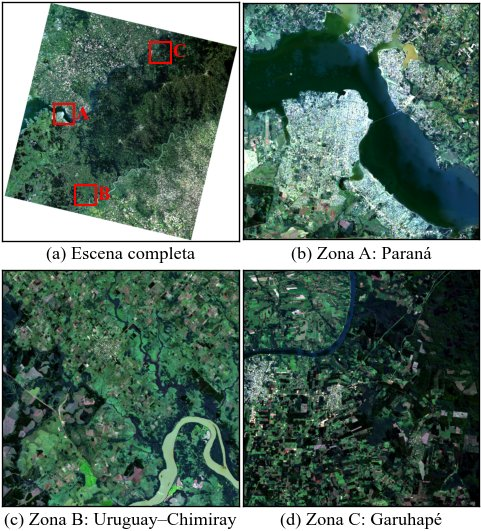

In [9]:
REDUCCION = 8
e = ESCENAS[FECHAS[0]]
reducida, LIM_NATURAL = [], {}
for b in (4, 3, 2):
    rho = a_reflectancia(leer_tif(e, f"SR_B{b}"), e, b)
    LIM_NATURAL[b] = np.nanpercentile(rho, (2, 98))
    reducida.append(cv2.resize(rho, None, fx=1 / REDUCCION, fy=1 / REDUCCION, interpolation=cv2.INTER_AREA))
del rho


def natural(img_bandas, limites=LIM_NATURAL):
    # img_bandas: función b -> banda 2D. Relleno en blanco.
    rgb = np.dstack([estirar(img_bandas(b), limites[b]) for b in (4, 3, 2)])
    return np.where(np.isnan(rgb), 1.0, rgb)


vista = natural(lambda b: reducida[(4, 3, 2).index(b)])

fig, axs = plt.subplots(2, 2, figsize=(ancho(0.6), ancho(0.6) + 0.45))
mostrar_img(axs[0, 0], vista, "Escena completa", "a")
for z, d in ZONAS.items():
    v = RECORTES[FECHAS[0]][z]["ventana"]
    f0, c0 = v[0].start / REDUCCION, v[1].start / REDUCCION
    lado = (v[0].stop - v[0].start) / REDUCCION
    axs[0, 0].add_patch(Rectangle((c0, f0), lado, lado, fill=False, ec="red", lw=1.2))
    axs[0, 0].text(c0 + lado + 6, f0 + lado / 2, d["letra"], color="red", fontsize=11,
                   fontweight="bold", va="center")
for ax, (z, d), letra in zip(axs.flat[1:], ZONAS.items(), "bcd"):
    mostrar_img(ax, natural(lambda b: banda(RECORTES[FECHAS[0]][z], b)), f"Zona {d['letra']}: {z}", letra)
guardar(fig, "zonas_ubicacion")
plt.show()

**Qué se observa.** El Paraná y el Uruguay se ven muy distintos en color natural. El Paraná, embalsado por Yacyretá, es oscuro: en un embalse la corriente se frena y los sedimentos decantan. El Uruguay se ve beige claro, con un brillo parecido al de los suelos: lleva mucho sedimento en suspensión. En el visible el agua no siempre es oscura; depende de su turbidez. En la zona B, el arroyo Chimiray casi no se distingue como agua: se reconoce sobre todo por la franja oscura de monte que lo acompaña, desde la esquina superior izquierda hasta el río.

### Reflectancias negativas

La corrección atmosférica puede dar reflectancias apenas negativas sobre superficies muy oscuras, como el agua en el SWIR. El rango válido que indica el USGS va de 0 a 1 ($DN$ entre 7273 y 43636). Se cuantifica cuántos píxeles quedan fuera antes de decidir qué hacer con ellos.

In [10]:
filas = []
for f, recortes in RECORTES.items():
    refl = np.concatenate([r["refl"].reshape(-1, 7) for r in recortes.values()])
    agua = np.concatenate([r["qa"]["agua"].ravel() for r in recortes.values()])
    for b in NOMBRES_BANDAS:
        x = refl[:, b - 1]
        filas.append({"Fecha": f, "Banda": f"B{b} {NOMBRES_BANDAS[b]}",
                      "Negativos [%]": 100 * np.mean(x < 0),
                      "Negativos en agua QA [%]": 100 * np.mean(x[agua] < 0),
                      "Mínimo": np.nanmin(x),
                      "Percentil 1 en agua QA": np.nanpercentile(x[agua], 1)})
pd.DataFrame(filas).set_index(["Banda", "Fecha"]).round(4)

,,Negativos [%],Negativos en agua QA [%],Mínimo,Percentil 1 en agua QA
Banda,Fecha,,,,
B1 Costera,03/04/2024,1.2996,9.6455,-0.1685,-0.0011
B2 Azul,03/04/2024,0.0202,0.0036,-0.1963,0.0088
B3 Verde,03/04/2024,0.0001,0.0000,-0.0008,0.0284
B4 Rojo,03/04/2024,0.0003,0.0006,-0.0067,0.0077
B5 NIR,03/04/2024,6.5566,52.1500,-0.0096,-0.0041
B6 SWIR 1,03/04/2024,0.0797,0.6342,-0.0113,0.0000
B7 SWIR 2,03/04/2024,0.0011,0.0078,-0.0233,0.0009
B1 Costera,30/06/2024,0.1653,0.0201,-0.1495,0.0043
B2 Azul,30/06/2024,0.0436,0.0018,-0.1836,0.0149


**Qué se observa.** En el visible los negativos son casi inexistentes. En el NIR, entre el 52 % y el 75 % de los píxeles de agua quedan apenas por debajo de 0, y en junio también más de la mitad en el SWIR 1. Son valores muy chicos (el mínimo es −0,01; el percentil 1 está en −0,004), es decir, ruido de la corrección atmosférica alrededor de 0 sobre un blanco que casi no refleja. Unos pocos píxeles de las bandas 1 a 4 llegan a −0,2, pero son menos del 1,3 %.

**Decisión.** Se recortan las reflectancias al rango válido $[0, 1]$. Descartar los negativos como inválidos eliminaría la mayor parte del agua en el NIR; dejarlos haría que los índices de agua superen el valor 1, que no tiene sentido físico (por ejemplo, NDWI = 1,25 con verde 0,036 y NIR −0,004). El costo es que muchos píxeles de agua quedan exactamente en 0 en el NIR y el SWIR, lo que se tiene en cuenta al interpretar sus histogramas.

In [11]:
for recortes in RECORTES.values():
    for r in recortes.values():
        np.clip(r["refl"], 0, 1, out=r["refl"])   # los NaN de relleno se conservan

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Escenas | Las dos de la cátedra: 03/04/2024 (Landsat 9) y 30/06/2024 (Landsat 8) | Permiten comparar fechas; nubes ≤ 0,02 % | — | — | Metadatos |
| Ubicación de los recortes | Por latitud y longitud, convertidas a fila y columna con el origen de cada escena | Las cuadrículas están corridas 50 columnas (1500 m) | Índices fijos de fila y columna (notebook de la cátedra y de 2025) | El mismo índice cae en lugares distintos en cada fecha | Metadatos (MTL y GeoTIFF) y correlación de fase |
| Alineación entre fechas | Sin remuestreo | El residuo es de 0,45 px por eje, sistemático y menor que un píxel | Corregir el residuo con interpolación | Suaviza la imagen; en la sección 7 se verificó que el corrimiento no se confirma en los bordes del agua | Métrica (correlación de fase) |
| Tamaño de las zonas | 20 km × 20 km (666 × 666 px) en las tres | Misma escala en las figuras y porcentajes comparables | — | — | — |
| Zona A | Centro (−27,375; −55,890) | Paraná entre las dos ciudades, puente y bahías del embalse | — | — | Visual |
| Zona B | Centro (−28,092; −55,664) | Incluye el tramo bajo del Chimiray (OpenStreetMap), su desembocadura y 3,1 % de agua según QA | Centro en el tramo bajo del Chimiray (−28,077; −55,690) | El Uruguay quedaba en una esquina: 1,7 % de agua | Métrica (agua según QA) |
| Zona C | Centro (−26,815; −54,935) | Codo del Paraná, desembocadura de un arroyo y arroyos afluentes en valles | — | — | Visual |
| Nubes y sombras de nube | Excluidas con `QA_PIXEL` (bits 1 a 4) | Solo aparecen en el Paraná en junio (0,4 % de la zona) | — | — | Métrica |
| Escala de color de la vista general | Percentiles 2–98 de toda la escena, iguales en los cuatro paneles | Método de la cátedra; colores comparables entre zonas | Percentiles por zona | Cada panel tendría su propia escala | Visual |
| Reflectancias negativas | Recorte a $[0, 1]$ | Son ruido alrededor de 0 (mínimo −0,01 en el NIR y el SWIR) | Descartarlas como inválidas, o dejarlas | Descartarlas elimina hasta el 75 % del agua en el NIR; dejarlas lleva los índices por encima de 1 | Métrica |

## 3. Firmas espectrales y elección de bandas

### Muestras por clase

Para elegir las bandas con datos, y no solo con la tabla de la consigna, se sigue el método del notebook `2_Espacios_de_Color_Criterio_Empirico` de la cátedra: tomar píxeles etiquetados de cada clase y medir, canal por canal, cuánto se separan. Acá cada banda de Landsat cumple el papel de un canal de color.

**Clases.** Dos tipos de agua y tres coberturas terrestres:

- **Agua del Paraná** (zona A): agua del embalse, con poco sedimento.
- **Agua del Uruguay** (zona B): agua con mucho sedimento en suspensión.
- **Vegetación** (zona B): un parche de monte y un cultivo o pastura.
- **Suelo desnudo** (zona C): campos sin cubierta vegetal, al norte del Paraná.
- **Urbano** (zona A): centro de Posadas.

**Cómo se ubicaron.** Los rectángulos de agua están a varios píxeles de la orilla y son agua según `QA_PIXEL` en las dos fechas, para evitar píxeles mezcla. Los de las coberturas terrestres se eligieron sobre la imagen y se verificó que no tuvieran agua. En abril casi no hay campos arados, así que el suelo desnudo se toma como los píxeles con poca vegetación del sector norte de la zona C: índice de vegetación de diferencia normalizada $\text{NDVI} = (\rho_5 - \rho_4)/(\rho_5 + \rho_4) < 0{,}3$ y sin agua. Se usa la misma idea de diferencia normalizada que los índices de agua de la sección 5.

In [12]:
# Rectángulos de muestra: (zona, fila0, fila1, col0, col1), en coordenadas del recorte de la zona
MUESTRAS = {
    "Agua del Paraná": [("Paraná", 151, 181, 200, 230), ("Paraná", 403, 433, 412, 442)],
    "Agua del Uruguay": [("Uruguay–Chimiray", 571, 587, 461, 477), ("Uruguay–Chimiray", 467, 477, 468, 478),
                         ("Uruguay–Chimiray", 628, 634, 438, 444)],
    "Vegetación": [("Uruguay–Chimiray", 545, 575, 305, 322),    # monte
                   ("Uruguay–Chimiray", 565, 590, 220, 240)],   # cultivo o pastura
    "Suelo desnudo": [("Garuhapé", 0, 150, 0, 350)],             # solo los píxeles con NDVI < 0,3
    "Urbano": [("Paraná", 270, 300, 295, 325)],                  # centro de Posadas
}
CLASES_AGUA = ["Agua del Paraná", "Agua del Uruguay"]
CLASES_TIERRA = ["Vegetación", "Suelo desnudo", "Urbano"]

# Colores validados para daltonismo (todas las parejas); el agua lleva línea llena y círculos,
# las coberturas terrestres línea de trazos y cuadrados, para no depender solo del color
ESTILOS = {
    "Agua del Paraná": dict(color="#2a78d6", ls="-", marker="o"),
    "Agua del Uruguay": dict(color="#eda100", ls="-", marker="o"),
    "Vegetación": dict(color="#008300", ls="--", marker="s"),
    "Suelo desnudo": dict(color="#e34948", ls="--", marker="s"),
    "Urbano": dict(color="#1baf7a", ls="--", marker="s"),
}


def dif_normalizada(refl, b1, b2):
    # (rho_b1 - rho_b2) / (rho_b1 + rho_b2), con las bandas numeradas como en Landsat
    x, y = refl[..., b1 - 1], refl[..., b2 - 1]
    with np.errstate(invalid="ignore", divide="ignore"):
        return (x - y) / (x + y)


def mascaras_clase(fecha, clase):
    # Máscara de la clase en cada zona: píxeles de sus rectángulos, válidos según QA_PIXEL
    mascaras = {}
    for z, f0, f1, c0, c1 in MUESTRAS[clase]:
        r = RECORTES[fecha][z]
        m = mascaras.setdefault(z, np.zeros(r["qa"]["valido"].shape, bool))
        usar = r["qa"]["valido"][f0:f1, c0:c1].copy()
        if clase == "Suelo desnudo":
            usar &= (dif_normalizada(r["refl"][f0:f1, c0:c1], 5, 4) < 0.3) & ~r["qa"]["agua"][f0:f1, c0:c1]
        m[f0:f1, c0:c1] |= usar
    return mascaras


def pixeles(fecha, clase, imagenes):
    # Píxeles (N, canales) de la clase, tomados de imagenes[zona] con forma (filas, columnas, canales)
    return np.concatenate([imagenes[z][m] for z, m in mascaras_clase(fecha, clase).items()])


MUESTRA = {f: {c: pixeles(f, c, {z: r["refl"] for z, r in RECORTES[f].items()}) for c in MUESTRAS}
           for f in FECHAS}

pd.DataFrame([
    {"Fecha": f, "Clase": c, "Píxeles": len(p),
     "NDVI medio": np.nanmean(dif_normalizada(p, 5, 4)),
     "Desvío del NDVI": np.nanstd(dif_normalizada(p, 5, 4))}
    for f in FECHAS for c, p in MUESTRA[f].items()
]).set_index(["Clase", "Fecha"]).round(3)

,,Píxeles,NDVI medio,Desvío del NDVI
Clase,Fecha,,,
Agua del Paraná,03/04/2024,1800,-0.996,0.028
Agua del Uruguay,03/04/2024,392,-0.684,0.033
Vegetación,03/04/2024,1010,0.810,0.053
Suelo desnudo,03/04/2024,460,0.263,0.026
Urbano,03/04/2024,900,0.311,0.135
Agua del Paraná,30/06/2024,1800,-1.000,0.004
Agua del Uruguay,30/06/2024,392,-0.666,0.005
Vegetación,30/06/2024,1010,0.765,0.075
Suelo desnudo,30/06/2024,5027,0.261,0.027


### Firmas espectrales

Reflectancia media de cada clase en cada banda, con su desvío estándar. Bandas: 1 costera, 2 azul, 3 verde, 4 rojo, 5 NIR, 6 SWIR 1, 7 SWIR 2.

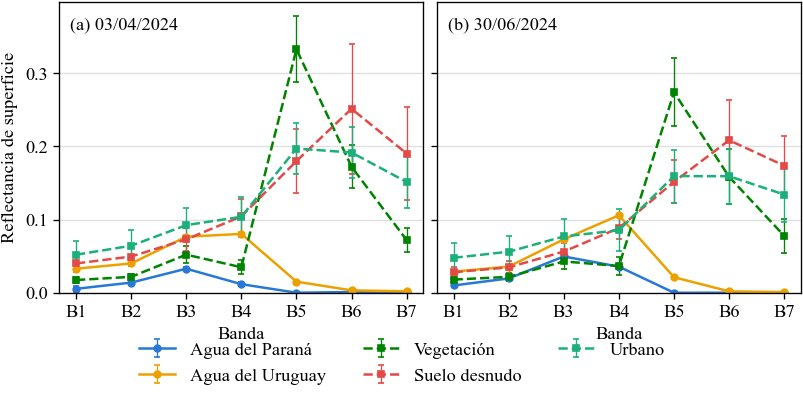

In [13]:
BANDAS = np.arange(1, 8)
fig, axs = plt.subplots(1, 2, figsize=(ancho(1.0), 3.4), sharey=True)
for ax, f, letra in zip(axs, FECHAS, "ab"):
    for clase, estilo in ESTILOS.items():
        p = MUESTRA[f][clase]
        ax.errorbar(BANDAS, p.mean(axis=0), yerr=p.std(axis=0), label=clase,
                    lw=1.5, ms=4, capsize=2, elinewidth=0.8, **estilo)
    ax.set_xticks(BANDAS, [f"B{b}" for b in BANDAS])
    ax.set_xlabel("Banda")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y")
    etiquetar(ax, letra, f)
axs[0].set_ylabel("Reflectancia de superficie")
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
guardar(fig, "firmas_espectrales")
plt.show()

In [14]:
# Reflectancia media por clase y banda
pd.DataFrame({(f, c): MUESTRA[f][c].mean(axis=0) for f in FECHAS for c in MUESTRAS},
             index=[f"B{b} {NOMBRES_BANDAS[b]}" for b in BANDAS]).T.round(3)

B1 Costera  B2 Azul  B3 Verde  B4 Rojo  B5 NIR  \
03/04/2024 Agua del Paraná        0.005    0.014     0.033    0.012   0.000   
           Agua del Uruguay       0.033    0.040     0.077    0.080   0.015   
           Vegetación             0.017    0.022     0.052    0.035   0.333   
           Suelo desnudo          0.040    0.049     0.073    0.104   0.180   
           Urbano                 0.052    0.064     0.092    0.104   0.197   
30/06/2024 Agua del Paraná        0.010    0.020     0.050    0.036   0.000   
           Agua del Uruguay       0.029    0.036     0.073    0.106   0.021   
           Vegetación             0.018    0.022     0.043    0.037   0.274   
           Suelo desnudo          0.028    0.035     0.056    0.088   0.152   
           Urbano                 0.048    0.056     0.077    0.085   0.160   

                             B6 SWIR 1  B7 SWIR 2  
03/04/2024 Agua del Paraná       0.001      0.002  
           Agua del Uruguay      0.003      0.002  
           Vegetación            0.172      0.072  
           Suelo desnudo         0.251      0.190  
           Urbano                0.192      0.151  
30/06/2024 Agua del Paraná       0.000      0.000  
           Agua del Uruguay      0.002      0.001  
           Vegetación            0.158      0.078  
           Suelo desnudo         0.209      0.174  
           Urbano                0.159      0.134

**Qué se observa.**

- **En el infrarrojo (B5 a B7) el agua es casi negra:** el Paraná queda en 0,000 a 0,002 y el Uruguay en 0,015 a 0,021 en el NIR, por el sedimento, y casi en 0 en los SWIR. Las tres coberturas terrestres reflejan mucho más: la vegetación, sobre todo en el NIR (0,33 en abril), y el suelo y la zona urbana, en el NIR y los SWIR (entre 0,13 y 0,25).
- **En el visible (B1 a B4) el agua se superpone con las coberturas terrestres:**
  - El agua clara del Paraná se parece a la vegetación, que también absorbe el azul y el rojo para la fotosíntesis. En el azul, 0,014 frente a 0,022 en abril.
  - El agua turbia del Uruguay es más brillante que la vegetación y se acerca al suelo y a la zona urbana. En el rojo llega a 0,080 en abril y a 0,106 en junio, por encima del suelo desnudo de junio (0,088).
- **En junio**, la vegetación refleja menos en el NIR (0,27 frente a 0,33) y el Paraná se ve más verde: su reflectancia sube en el verde (0,050 frente a 0,033) y en el rojo (0,036 frente a 0,012). La causa del cambio de color, sea fitoplancton o sedimento fino, no se puede determinar solo con estas bandas.

### Separabilidad entre el agua y las demás clases

Se usan dos de las métricas del notebook 2 de la cátedra, calculadas banda por banda entre cada tipo de agua y cada cobertura terrestre:

- **Razón de Fisher:** $F = \dfrac{(\mu_a - \mu_b)^2}{\sigma_a^2 + \sigma_b^2}$. Cuanto mayor, más separadas están las medias en relación con la dispersión de cada clase.
- **Coeficiente de solapamiento:** $\text{OVL} = \sum_k \min\big(p_a(k), p_b(k)\big)$, con los histogramas normalizados de las dos clases. Va de 0 (sin solapamiento) a 1 (distribuciones iguales) y no supone distribuciones normales.

Para detectar agua importa la cobertura terrestre que más se le parece, así que el resumen toma, para cada banda, **la peor pareja**: el menor $F$ y el mayor OVL entre el agua y las tres coberturas.

In [15]:
def fisher(a, b):
    # Razón de Fisher por banda entre dos conjuntos de píxeles (N, 7)
    return (a.mean(axis=0) - b.mean(axis=0)) ** 2 / (a.var(axis=0) + b.var(axis=0) + 1e-9)


def solapamiento(a, b, bins=50):
    # Coeficiente de solapamiento por banda entre dos conjuntos de píxeles (N, 7)
    ovl = []
    for k in range(a.shape[1]):
        lo = min(a[:, k].min(), b[:, k].min())
        hi = max(a[:, k].max(), b[:, k].max())
        ha, _ = np.histogram(a[:, k], bins=bins, range=(lo, hi))
        hb, _ = np.histogram(b[:, k], bins=bins, range=(lo, hi))
        ovl.append(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())
    return np.array(ovl)


filas = []
for f in FECHAS:
    for agua in CLASES_AGUA:
        for tierra in CLASES_TIERRA:
            a, b = MUESTRA[f][agua], MUESTRA[f][tierra]
            for metrica, valores in (("F", fisher(a, b)), ("OVL", solapamiento(a, b))):
                filas.append({"Fecha": f, "Agua": agua, "Cobertura": tierra, "Métrica": metrica,
                              **{f"B{b}": v for b, v in zip(BANDAS, valores)}})
SEPARABILIDAD = pd.DataFrame(filas).set_index(["Métrica", "Fecha", "Agua", "Cobertura"])
SEPARABILIDAD.round(2)

,,,,B1,B2,B3,B4,B5,B6,B7
Métrica,Fecha,Agua,Cobertura,,,,,,,
F,03/04/2024,Agua del Paraná,Vegetación,4.14,2.00,2.44,5.11,53.67,33.63,18.25
OVL,03/04/2024,Agua del Paraná,Vegetación,0.05,0.25,0.16,0.09,0.00,0.00,0.00
F,03/04/2024,Agua del Paraná,Suelo desnudo,8.14,6.46,5.97,14.80,17.38,8.01,8.91
OVL,03/04/2024,Agua del Paraná,Suelo desnudo,0.00,0.00,0.01,0.00,0.00,0.00,0.00
F,03/04/2024,Agua del Paraná,Urbano,5.53,5.62,6.58,11.03,31.84,30.22,18.31
OVL,03/04/2024,Agua del Paraná,Urbano,0.02,0.01,0.00,0.00,0.00,0.00,0.00
F,03/04/2024,Agua del Uruguay,Vegetación,12.56,15.94,4.04,20.89,48.74,32.61,17.89
OVL,03/04/2024,Agua del Uruguay,Vegetación,0.00,0.00,0.01,0.00,0.00,0.00,0.00
F,03/04/2024,Agua del Uruguay,Suelo desnudo,0.40,0.48,0.05,1.00,14.53,7.86,8.87


In [16]:
# Peor pareja por banda: menor F y mayor OVL entre cada tipo de agua y las coberturas terrestres
PEOR_F = SEPARABILIDAD.loc["F"].groupby(level=["Fecha", "Agua"]).min()
PEOR_OVL = SEPARABILIDAD.loc["OVL"].groupby(level=["Fecha", "Agua"]).max()
display(PEOR_F.round(1), PEOR_OVL.round(2))

B1   B2   B3   B4    B5    B6    B7
Fecha      Agua                                                  
03/04/2024 Agua del Paraná   4.1  2.0  2.4  5.1  17.4   8.0   8.9
           Agua del Uruguay  0.4  0.5  0.0  0.7  14.5   7.9   8.9
30/06/2024 Agua del Paraná   3.0  0.2  0.3  0.0  19.4  14.4  11.2
           Agua del Uruguay  0.0  0.0  0.0  0.5  14.6  14.1  11.0

B1    B2    B3    B4   B5   B6   B7
Fecha      Agua                                                   
03/04/2024 Agua del Paraná   0.05  0.25  0.16  0.09  0.0  0.0  0.0
           Agua del Uruguay  0.11  0.13  0.25  0.14  0.0  0.0  0.0
30/06/2024 Agua del Paraná   0.19  0.28  0.28  0.18  0.0  0.0  0.0
           Agua del Uruguay  0.29  0.19  0.16  0.08  0.0  0.0  0.0

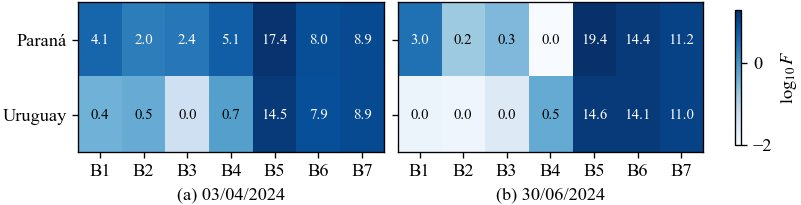

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(ancho(1.0), 1.75), sharey=True)
escala = np.log10(np.clip(PEOR_F.to_numpy(), 1e-2, None))
lim = (escala.min(), escala.max())
for ax, f, letra in zip(axs, FECHAS, "ab"):
    datos = PEOR_F.loc[f].loc[CLASES_AGUA]
    im = ax.imshow(np.log10(np.clip(datos.to_numpy(), 1e-2, None)), cmap="Blues",
                   vmin=lim[0], vmax=lim[1], aspect="auto")
    for (i, j), v in np.ndenumerate(datos.to_numpy()):
        oscuro = np.log10(max(v, 1e-2)) > lim[0] + 0.6 * (lim[1] - lim[0])
        ax.text(j, i, f"{v:.1f}" if v < 100 else f"{v:.0f}", ha="center", va="center",
                fontsize=9, color="white" if oscuro else "black")
    ax.set_xticks(range(7), [f"B{b}" for b in BANDAS])
    ax.set_yticks(range(len(CLASES_AGUA)), [c.replace("Agua del ", "") for c in CLASES_AGUA])
    ax.set_xlabel(f"({letra}) {f}")
fig.colorbar(im, ax=axs, label=r"$\log_{10} F$", shrink=0.9)
guardar(fig, "separabilidad_fisher")
plt.show()

**Qué se observa.**

- **El NIR (B5) es la banda que mejor separa el agua** de la cobertura más parecida, en los dos tipos de agua y en las dos fechas: F entre 14,5 y 19,4. Le siguen el SWIR 1 (B6, entre 7,9 y 14,4) y el SWIR 2 (B7, entre 8,9 y 11,2).
- **En el infrarrojo no hay solapamiento:** el OVL vale 0 en B5, B6 y B7 para todas las parejas.
- **En el visible la peor pareja nunca supera F = 5,1:** el OVL llega a 0,29. Para el agua turbia del Uruguay, F es menor que 1 frente al suelo y la zona urbana en todas las bandas visibles.
- **El azul (B2) separa poco:** su peor F es 2,0 (Paraná, abril), 0,2 (Paraná, junio), 0,5 y 0,0 (Uruguay). La justificación de la consigna para la banda 2 ("el agua absorbe mucha luz en esta banda, lo que la hace aparecer oscura") no se sostiene con estos datos: el agua clara refleja en el azul tanto como la vegetación, y el agua turbia refleja más.

### Selección de bandas

- **B5 (NIR):** es la base de cualquier combinación para detectar agua, porque es la que más la separa y no tiene solapamiento.
- **B6 y B7 (SWIR):** son el segundo y el tercer criterio. Tienen una separabilidad algo menor, pero también sin solapamiento. Además, el SWIR es la banda en la que el suelo desnudo y la zona urbana se diferencian de la vegetación, así que suma información sobre las coberturas terrestres.
- **B2 (azul):** no sirve para **detectar** agua, pero sí para **caracterizarla**. Es la banda que distingue el agua clara del Paraná de la turbia del Uruguay (0,014 frente a 0,040 en abril).

Por eso la composición de la consigna (bandas 2, 5 y 7) se justifica por B5 y B7. B2 aporta el color del agua y no el contraste con la tierra. En la sección siguiente se compara con la 5-6-4 de la tabla de la cátedra, que usa las dos bandas más separables (B5 y B6).

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Método para elegir bandas | Muestras por clase y separabilidad banda por banda (Fisher y solapamiento) | Es el método del notebook 2 de la cátedra; justifica la elección con números | Estadística M (Kaufman y Remer, 1994) | No es de la materia | — |
| Clases | Agua del Paraná, agua del Uruguay, vegetación, suelo desnudo y urbano | Dos tipos de agua bien distintos y las coberturas terrestres de las tres zonas | Siete clases: agua de bahía como tercer tipo de agua, y monte y cultivo por separado | Con siete series no hay paleta que pase la validación para daltonismo; la bahía es agua turbia como el Uruguay; monte y cultivo tienen firmas parecidas (NDVI 0,79 y 0,83) | Validador de paleta y métrica |
| Rectángulos de agua | A varios píxeles de la orilla y agua según QA en las dos fechas | Evita píxeles mezcla | Rectángulos ubicados a ojo | Uno del Paraná tenía solo 31 % de agua | Métrica (agua QA) |
| Suelo desnudo | Píxeles con NDVI < 0,3 y sin agua, en el sector norte de la zona C | En abril casi no hay campos arados | Rectángulos de campos que se ven rosados en color natural | Tenían NDVI entre 0,65 y 0,74: eran vegetación | Métrica (NDVI) |
| Sombra de relieve | No se muestrea como clase | A 30 m las laderas en sombra miden pocos píxeles y se mezclan con los arroyos de los valles, también oscuros en el NIR; sin un modelo de elevación no se separan. Su efecto se mide en las secciones 5 y 7 | Rectángulos sobre laderas | — | Visual |
| Resumen de separabilidad | Peor pareja por banda (menor F y mayor OVL) | Para detectar agua importa la cobertura que más se le parece | Promedio entre coberturas | Ocultaría la confusión con la cobertura más parecida | — |
| Bandas para el agua | B5, luego B6 y B7; B2 solo para caracterizar el agua | B5: peor F entre 14,5 y 19,4; B6 y B7: entre 7,9 y 14,4; OVL = 0 en las tres. B2: peor F entre 0,0 y 2,0 | B2 como banda de detección (consigna) | El agua clara refleja en el azul como la vegetación, y la turbia, más | Métrica (Fisher y OVL) |

## 4. Composiciones RGB y mejora de contraste

### Estiramiento común a las zonas y las fechas

Para que un mismo color signifique lo mismo en todas las figuras, los parámetros de cada mejora de contraste se calculan una sola vez por banda, con los píxeles válidos de las tres zonas en las dos fechas juntas. Si cada recorte se estirara por separado, el agua del Paraná y la del Uruguay podrían terminar con el mismo gris aunque reflejen distinto.

In [18]:
TODOS = np.concatenate([r["refl"][r["qa"]["valido"]] for f in FECHAS for r in RECORTES[f].values()])
sin_dato = np.isnan(TODOS).any(axis=1)   # DN = 0 en alguna banda, aunque QA no lo marque como relleno
print(f"Píxeles válidos: {len(TODOS)}; con alguna banda sin dato: {sin_dato.sum()}")
TODOS = TODOS[~sin_dato]
LIM_MINMAX = {b: (TODOS[:, b - 1].min(), TODOS[:, b - 1].max()) for b in BANDAS}
LIM_PERC = {b: tuple(np.percentile(TODOS[:, b - 1], (2, 98))) for b in BANDAS}


def curva_ecualizacion(x, niveles=4096):
    # Ecualización global del notebook 10: CDF de los valores, con el mínimo llevado a 0
    hist, bordes = np.histogram(x, bins=niveles, range=(0, x.max()))
    cdf = hist.cumsum() / hist.sum()
    cdf_min = cdf[hist > 0][0]
    return bordes, np.clip((cdf - cdf_min) / (1 - cdf_min), 0, 1)


CURVA_EQ = {b: curva_ecualizacion(TODOS[:, b - 1]) for b in BANDAS}
del TODOS

pd.DataFrame({"Mínimo": {f"B{b}": v[0] for b, v in LIM_MINMAX.items()},
              "Percentil 2": {f"B{b}": v[0] for b, v in LIM_PERC.items()},
              "Percentil 98": {f"B{b}": v[1] for b, v in LIM_PERC.items()},
              "Máximo": {f"B{b}": v[1] for b, v in LIM_MINMAX.items()}}).T.round(3)

Píxeles válidos: 2659396; con alguna banda sin dato: 5


,B1,B2,B3,B4,B5,B6,B7
Mínimo,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Percentil 2,0.001,0.006,0.018,0.010,0.000,0.000,0.000
Percentil 98,0.048,0.058,0.086,0.104,0.391,0.249,0.175
Máximo,0.514,0.587,0.666,0.658,0.775,1.000,1.000


### Las bandas seleccionadas en las tres zonas

Antes de combinar bandas, se mira cada una por separado en escala de grises, con el estiramiento de percentiles 2 y 98 común a las tres zonas. Es la versión visual de la separabilidad medida en la sección anterior: el agua debería verse negra en B5, B6 y B7, y no necesariamente en B2.

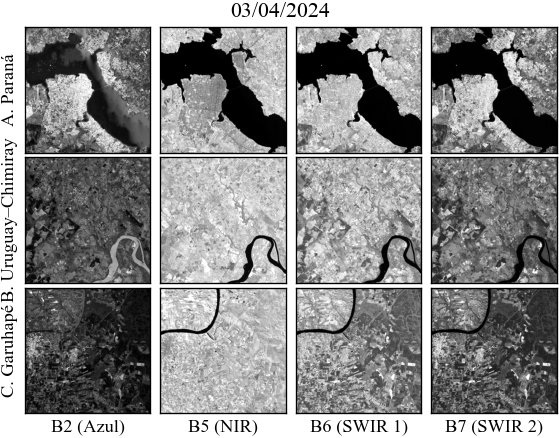

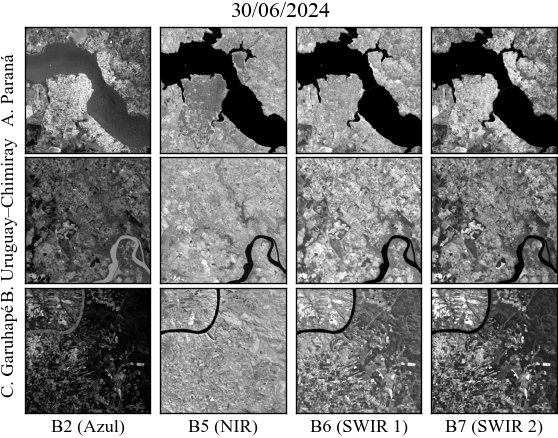

In [19]:
BANDAS_GRISES = [2, 5, 6, 7]


def grilla_zonas(fecha, columnas, imagen, rotulos, nombre):
    # Filas: zonas. Columnas: lo que devuelve imagen(fecha, zona, columna). Rótulos debajo de la última fila.
    fig, axs = plt.subplots(len(ZONAS), len(columnas), figsize=(ancho(0.7), 3.65))
    for i, (z, d) in enumerate(ZONAS.items()):
        for j, col in enumerate(columnas):
            ax = axs[i, j]
            img = imagen(fecha, z, col)
            ax.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(f"{d['letra']}. {z}")
            if i == len(ZONAS) - 1:
                ax.set_xlabel(rotulos[j])
    fig.suptitle(fecha)
    guardar(fig, nombre)
    plt.show()


for f in FECHAS:
    grilla_zonas(f, BANDAS_GRISES,
                 lambda f, z, b: estirar(banda(RECORTES[f][z], b), LIM_PERC[b]),
                 [f"B{b} ({NOMBRES_BANDAS[b]})" for b in BANDAS_GRISES],
                 "bandas_zonas" if f == FECHAS[0] else "")

**Qué se observa.**

- **En B2 el agua no es oscura:** el Uruguay se ve gris claro, tanto o más que los campos, y el Paraná gris medio.
- **En B5, B6 y B7 el agua es negra en las tres zonas** y su borde queda nítido.
- **En B5 la tierra es clara y bastante uniforme,** porque casi todo refleja mucho en el NIR. En la zona B se insinúan algunos arroyos como líneas oscuras finas; se analizan en la sección de agua grande y chica.
- **En B6 y B7** la ciudad y los suelos se ven más claros que la vegetación, así que la tierra muestra más variedad, mientras el agua sigue negra.

Es lo mismo que midió la razón de Fisher, ahora visible.

### Métodos de mejora de contraste

Se comparan cuatro transformaciones de cada banda a $[0, 1]$:

- **Lineal mínimo–máximo:** sin mejora. Es la referencia.
- **Percentiles 2–98:** estiramiento lineal recortando el 2 % de cada extremo (notebooks 6 y 10).
- **Ecualización global:** transformación por la CDF, como `normalize_histogram` del notebook 10.
- **CLAHE:** ecualización por regiones con límite de contraste (notebooks 1 y 6), con `clipLimit = 2` y una grilla de 8 × 8 celdas (unos 2,5 km por celda). Por ser local, sus resultados no se pueden comparar entre zonas ni entre fechas.

Para elegir el método no alcanza con la apreciación visual. Se mide la **diferencia de color percibida** entre clases, sobre los mismos píxeles de muestra de la sección anterior: se pasa la composición a CIELAB (el espacio de color perceptualmente uniforme visto en la unidad 2) y se calcula $\Delta E = \lVert \text{Lab}_a - \text{Lab}_b \rVert$ entre los colores medios de cada clase. Como valor de referencia, una diferencia de unos 2,3 unidades es apenas perceptible (Sharma, 2003).

- **Agua–tierra:** el menor $\Delta E$ entre un tipo de agua y una cobertura terrestre. Mide qué tan bien resalta el agua.
- **Entre aguas:** $\Delta E$ entre el Paraná y el Uruguay. Mide si la composición distingue agua clara de agua turbia.

In [20]:
def ecualizar(x, b):
    bordes, curva = CURVA_EQ[b]
    k = np.clip(np.searchsorted(bordes, x, side="right") - 1, 0, len(curva) - 1)
    return curva[k]


def clahe(x, b, clip=2.0, celdas=8):
    # CLAHE en 16 bits sobre la banda ya estirada entre los percentiles 2 y 98
    u = np.round(65535 * np.nan_to_num(estirar(x, LIM_PERC[b]))).astype(np.uint16)
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(celdas, celdas)).apply(u) / 65535


CONTRASTE = {
    "Lineal mín–máx": lambda x, b: estirar(x, LIM_MINMAX[b]),
    "Percentiles 2–98": lambda x, b: estirar(x, LIM_PERC[b]),
    "Ecualización global": ecualizar,
    "CLAHE": clahe,
}

COMPOSICIONES = {
    "4-3-2": "color natural",
    "2-5-7": "bandas de la consigna, R = B2",
    "7-5-2": "bandas de la consigna, R = B7",
    "5-6-4": "tierra y agua (tabla)",
    "7-6-5": "las tres más separables",
}


def componer(fecha, zona, bandas, metodo):
    # bandas: texto "R-G-B", por ejemplo "7-5-2"
    refl = RECORTES[fecha][zona]["refl"]
    return np.dstack([CONTRASTE[metodo](refl[..., int(b) - 1], int(b)) for b in bandas.split("-")])


def diferencias_color(fecha, imagenes):
    # Delta E (CIE76) entre los colores medios de las clases, con los píxeles de muestra
    lab = {z: color.rgb2lab(img) for z, img in imagenes.items()}
    medio = {c: pixeles(fecha, c, lab).mean(axis=0) for c in MUESTRAS}
    agua_tierra = min(np.linalg.norm(medio[a] - medio[t]) for a in CLASES_AGUA for t in CLASES_TIERRA)
    return agua_tierra, np.linalg.norm(medio[CLASES_AGUA[0]] - medio[CLASES_AGUA[1]])


filas = []
for f in FECHAS:
    for comp in COMPOSICIONES:
        for metodo in CONTRASTE:
            dif = diferencias_color(f, {z: componer(f, z, comp, metodo) for z in ZONAS})
            filas.append({"Fecha": f, "Composición": comp, "Método": metodo,
                          "ΔE agua–tierra": dif[0], "ΔE entre aguas": dif[1]})
DELTA_E = pd.DataFrame(filas)
DELTA_E.pivot_table(index=["Composición"], columns=["Fecha", "Método"],
                    values="ΔE agua–tierra").round(1)

Fecha       03/04/2024                                                      \
Método           CLAHE Ecualización global Lineal mín–máx Percentiles 2–98   
Composición                                                                  
2-5-7             75.9                93.8           27.7             78.6   
4-3-2             22.6                 4.8            4.1             27.4   
5-6-4             74.7                78.3           24.6             78.7   
7-5-2             56.3                53.8           35.0             61.5   
7-6-5             64.7                69.0           22.0             72.7   

Fecha       30/06/2024                                                      
Método           CLAHE Ecualización global Lineal mín–máx Percentiles 2–98  
Composición                                                                 
2-5-7             64.5                66.4           22.5             68.3  
4-3-2             25.1                13.8            2.2             26.2  
5-6-4             67.0                70.0           21.5             73.2  
7-5-2             55.0                48.8           29.4             50.5  
7-6-5             56.9                58.4           17.1             64.9

In [21]:
DELTA_E.pivot_table(index=["Composición"], columns=["Fecha", "Método"], values="ΔE entre aguas").round(1)

Fecha       03/04/2024                                                      \
Método           CLAHE Ecualización global Lineal mín–máx Percentiles 2–98   
Composición                                                                  
2-5-7             69.2                78.7            3.4             66.2   
4-3-2             69.7                69.7           10.2             66.3   
5-6-4            114.3               121.2           15.9            106.6   
7-5-2             77.6                85.5            3.7             74.6   
7-6-5              2.5                 3.7            1.8              3.2   

Fecha       30/06/2024                                                      
Método           CLAHE Ecualización global Lineal mín–máx Percentiles 2–98  
Composición                                                                 
2-5-7             46.5                45.5            3.3             40.0  
4-3-2             54.9                39.6           12.1             56.7  
5-6-4             87.8                48.8           20.1             89.3  
7-5-2             49.2                49.3            2.5             40.8  
7-6-5              2.9                 3.7            2.6              5.0

In [22]:
# Método: el que da el mayor ΔE agua–tierra en más casos (cada composición en cada fecha)
mejor = DELTA_E.loc[DELTA_E.groupby(["Fecha", "Composición"])["ΔE agua–tierra"].idxmax()]
print("Casos en que cada método da el mayor ΔE agua–tierra:")
print(mejor["Método"].value_counts().to_string())
METODO = mejor["Método"].value_counts().idxmax()

# Orden de la composición de la consigna: el de mayor ΔE agua–tierra con ese método (promedio de las fechas)
CON_METODO = (DELTA_E[DELTA_E["Método"] == METODO]
              .groupby("Composición")[["ΔE agua–tierra", "ΔE entre aguas"]].mean())
ORDEN_CONSIGNA = CON_METODO.loc[["2-5-7", "7-5-2"], "ΔE agua–tierra"].idxmax()
print(f"\nMétodo elegido: {METODO}. Orden de la consigna: {ORDEN_CONSIGNA}")
CON_METODO.sort_values("ΔE agua–tierra", ascending=False).round(1)

Casos en que cada método da el mayor ΔE agua–tierra:
Método
Percentiles 2–98       8
Ecualización global    1
CLAHE                  1

Método elegido: Percentiles 2–98. Orden de la consigna: 2-5-7


,ΔE agua–tierra,ΔE entre aguas
Composición,,
5-6-4,75.9,98.0
2-5-7,73.4,53.1
7-6-5,68.8,4.1
7-5-2,56.0,57.7
4-3-2,26.8,61.5


**Qué se observa.**

- **Lineal mínimo–máximo:** las imágenes quedan oscuras, con ΔE agua–tierra de 35 como máximo. Unos pocos píxeles muy brillantes, como techos con 0,78 en el NIR y 1,0 en el SWIR, fijan el máximo y comprimen todo lo demás.
- **Percentiles 2–98:** da el mayor ΔE agua–tierra en 8 de los 10 casos. Como es la misma transformación lineal en todas las zonas y fechas, los colores se pueden comparar.
- **Ecualización global:** gana en un caso (93,8 en la 2-5-7 de abril), pero es muy variable: cae a 4,8 en la 4-3-2 de abril. Además exagera la textura de los campos.
- **CLAHE:** da valores parecidos, pero es local: el mismo valor de reflectancia puede quedar con colores distintos según la zona. Como resalta los detalles locales, se va a usar para mirar los arroyos.

**Orden de los canales.** La 2-5-7 (R = B2) da más contraste entre agua y tierra que la 7-5-2: 73,4 frente a 56,0 en promedio. El agua queda roja sobre una tierra verde o violácea. Por eso se usa la 2-5-7. El notebook de 2025 usaba la 7-5-2 en el código, pero el informe describía la 2-5-7.

**Composiciones.**

- **La 5-6-4 de la tabla de la cátedra es la mejor en las dos métricas:** ΔE agua–tierra de 75,9 y entre aguas de 98,0. Su canal azul es B4, la banda en la que el agua turbia refleja más (0,08 a 0,106), así que el Uruguay se ve azul y el Paraná casi negro.
- **La 2-5-7 de la consigna** contrasta casi tanto el agua con la tierra (73,4), pero distingue menos los dos tipos de agua (53,1).
- **La 7-6-5, con las tres bandas más separables según Fisher,** no da el mayor contraste (68,8) y no distingue el agua clara de la turbia (4,1, por debajo del umbral de percepción): ninguna banda infrarroja ve el sedimento.
- **La 4-3-2 es la peor para resaltar agua (26,8):** el Uruguay turbio se confunde con el suelo.

La separabilidad por banda es necesaria, pero no alcanza: el resultado depende también de cómo se asignan las bandas a los colores. Una banda visible, B2 o B4, le da al agua un color que indica su tipo.

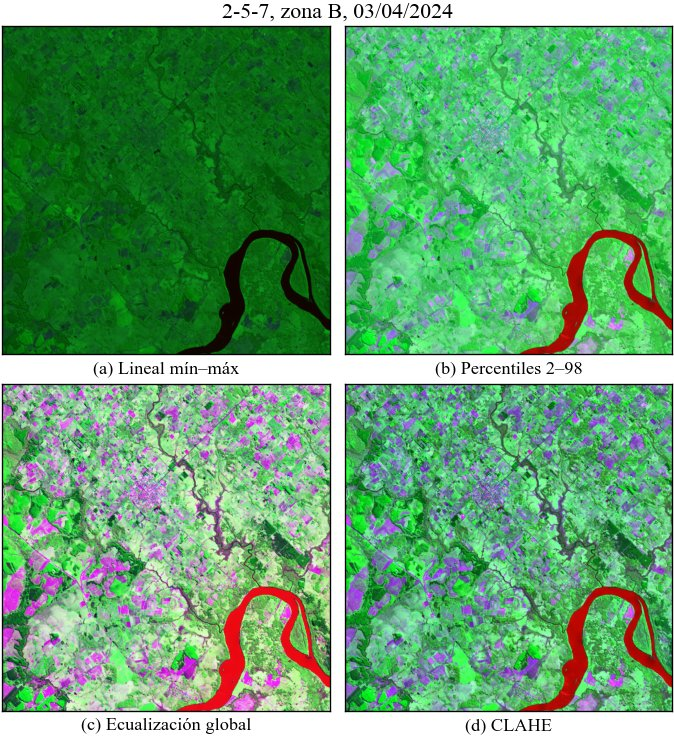

In [23]:
# Los cuatro métodos sobre la composición de la consigna en la zona B (agua turbia y arroyos), en abril
fig, axs = plt.subplots(2, 2, figsize=(ancho(0.85), ancho(0.85) + 0.45))
for ax, metodo, letra in zip(axs.flat, CONTRASTE, "abcd"):
    mostrar_img(ax, componer(FECHAS[0], "Uruguay–Chimiray", ORDEN_CONSIGNA, metodo), metodo, letra)
fig.suptitle(f"{ORDEN_CONSIGNA}, zona B, {FECHAS[0]}")
guardar(fig, "contraste_metodos")
plt.show()

### Orden de los canales en la composición de la consigna

La consigna indica las bandas 2, 5 y 7, pero no a qué canal va cada una. El orden cambia los colores, aunque no la información: con R = B2, G = B5 y B = B7, el agua turbia se ve rojiza; con R = B7, G = B5 y B = B2, el agua queda en el canal azul, que es la única banda de las tres en la que refleja algo. Se comparan las dos con el método elegido.

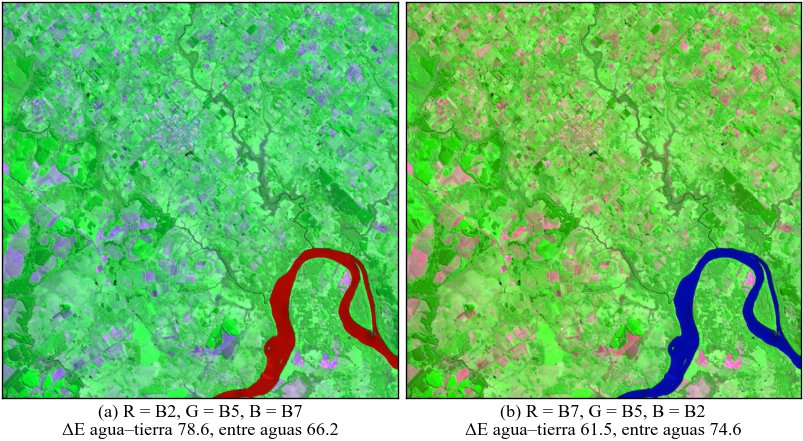

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(ancho(1.0), ancho(1.0) / 2 + 0.5))
for ax, comp, letra in zip(axs, ["2-5-7", "7-5-2"], "ab"):
    r, g, b = comp.split("-")
    dif = DELTA_E.query("Fecha == @FECHAS[0] and Composición == @comp and Método == @METODO").iloc[0]
    mostrar_img(ax, componer(FECHAS[0], "Uruguay–Chimiray", comp, METODO),
                f"R = B{r}, G = B{g}, B = B{b}\nΔE agua–tierra {dif['ΔE agua–tierra']:.1f}, "
                f"entre aguas {dif['ΔE entre aguas']:.1f}", letra)
plt.show()

### Composiciones en las tres zonas

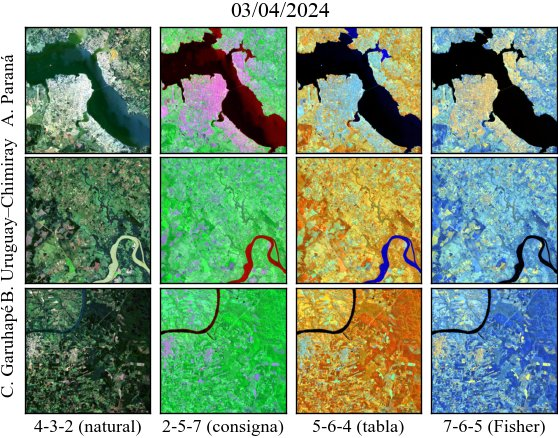

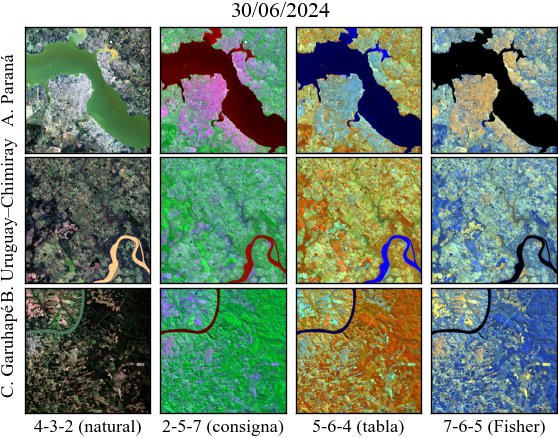

In [25]:
GRILLA = ["4-3-2", ORDEN_CONSIGNA, "5-6-4", "7-6-5"]
ROTULOS_COMP = {"4-3-2": "natural", "2-5-7": "consigna", "7-5-2": "consigna", "5-6-4": "tabla", "7-6-5": "Fisher"}
for f in FECHAS:
    grilla_zonas(f, GRILLA, lambda f, z, comp: componer(f, z, comp, METODO),
                 [f"{comp} ({ROTULOS_COMP[comp]})" for comp in GRILLA],
                 "composiciones_zonas" if f == FECHAS[0] else "")

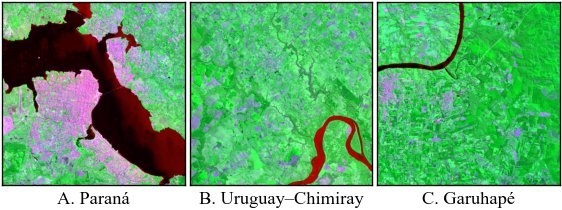

In [26]:
# Composición de la consigna (2-5-7) en las tres zonas, para el informe
fig, axs = plt.subplots(1, len(ZONAS), figsize=(ancho(0.7), 1.95))
for ax, (z, d) in zip(axs, ZONAS.items()):
    ax.imshow(componer(FECHAS[0], z, ORDEN_CONSIGNA, METODO))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"{d['letra']}. {z}")
guardar(fig, "composiciones_seleccionadas")
plt.show()

**Qué se observa.**

- **Zona A:** en las tres composiciones con infrarrojo, el Paraná y sus bahías quedan bien recortados. En la 5-6-4, la bahía turbia de la margen paraguaya se ve azul y el embalse casi negro, así que también se distingue la turbidez. Posadas se ve rosada en la 2-5-7 y celeste en la 5-6-4.
- **Zona B:** el Uruguay se delimita sin ambigüedad. Los arroyos aparecen como líneas oscuras: se ve el corredor de monte que los acompaña, no el color del agua. A 30 m, la composición resalta su recorrido pero no el agua en sí.
- **Zona C:** el Paraná y la desembocadura de un arroyo cerca de Garuhapé se ven como agua. Los arroyos chicos se ven como líneas oscuras dentro del monte, junto con la textura del relieve.
- **En junio el patrón se repite:** el Paraná se ve más verde en la 4-3-2 y azul oscuro en la 5-6-4 (su reflectancia en el rojo subió), y la textura del relieve de la zona C se marca más por el sol bajo.

**¿Cumplieron con el objetivo?** Sí para los ríos: con cualquier composición que incluya B5 y una banda SWIR, el Paraná, el Uruguay y las bahías quedan delimitados en las dos fechas. Para los arroyos, solo en parte: se reconoce su corredor, pero no se ven como agua. Eso se mide en la sección de agua grande y chica.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Estiramiento | Parámetros calculados con las tres zonas en las dos fechas | Un mismo color representa la misma reflectancia en todas las figuras | Estirar cada recorte por separado | El mismo gris podría representar reflectancias distintas | — |
| Métrica de contraste | ΔE (CIE76) en CIELAB entre los colores medios de las clases | Mide la diferencia de color percibida, sobre los píxeles de muestra | Contraste RMS de la imagen | No distingue si el contraste está entre agua y tierra o dentro de los campos | — |
| Método de contraste | Percentiles 2–98 | Mayor ΔE agua–tierra en 8 de 10 casos; misma transformación lineal en todas las zonas | Ecualización global y CLAHE | La ecualización varía mucho (de 4,8 a 93,8) y exagera la textura; CLAHE es local y no se puede comparar entre zonas | Métrica (ΔE) |
| Tercera variante del notebook 10 | No se usa | Calcula los percentiles sobre la tabla de 65 536 niveles de la CDF y no sobre los píxeles, así que su efecto depende de en qué parte del rango de 16 bits caen los datos | — | — | Análisis del código |
| Orden de los canales de la consigna | R = B2, G = B5, B = B7 | ΔE agua–tierra de 73,4 frente a 56,0 (promedio de las fechas) | R = B7, G = B5, B = B2 (agua en azul) | Menos contraste entre agua y tierra | Métrica (ΔE) |
| Composición recomendada | 5-6-4 | Mayor ΔE agua–tierra (75,9) y entre aguas (98,0) | 7-6-5, con las tres bandas más separables | No distingue el agua clara de la turbia (ΔE 4,1) | Métrica (ΔE) |

## 5. Índices de agua y segmentación

### Índices

Un índice combina bandas en un solo valor por píxel. Las composiciones de la sección anterior sirven para mirar; un índice permite **umbralizar** y medir. Se usan tres índices de la bibliografía de teledetección, construidos con las bandas que la sección 3 mostró como más separables:

- **NDWI** (McFeeters, 1996): $\dfrac{\rho_3 - \rho_5}{\rho_3 + \rho_5}$. El agua refleja más en el verde que en el NIR, así que da positivo; la vegetación, negativo.
- **MNDWI** (Xu, 2006): $\dfrac{\rho_3 - \rho_6}{\rho_3 + \rho_6}$. Reemplaza el NIR por el SWIR 1 para reducir la confusión con las zonas urbanas, que en el NDWI pueden dar valores cercanos a los del agua.
- **AWEIsh** (Feyisa et al., 2014): $\rho_2 + 2{,}5\,\rho_3 - 1{,}5\,(\rho_5 + \rho_6) - 0{,}25\,\rho_7$. Fue diseñado para descartar las sombras, que son oscuras en todas las bandas como el agua. Usa las bandas 2, 5 y 7 de la consigna. No está normalizado, así que su rango no es $[-1, 1]$.

En los tres, el umbral nominal entre agua y tierra es 0. NDWI y MNDWI son diferencias normalizadas, la misma idea de los índices de color del notebook de agricultura de precisión de la cátedra: el cociente cancela en buena parte las variaciones de iluminación.

In [27]:
INDICES = {
    "NDWI": lambda r: dif_normalizada(r, 3, 5),
    "MNDWI": lambda r: dif_normalizada(r, 3, 6),
    "AWEIsh": lambda r: r[..., 1] + 2.5 * r[..., 2] - 1.5 * (r[..., 4] + r[..., 5]) - 0.25 * r[..., 6],
}
IND = {f: {z: {n: g(RECORTES[f][z]["refl"]) for n, g in INDICES.items()} for z in ZONAS} for f in FECHAS}

# Valor de cada índice en las clases de muestra, y separabilidad del agua (peor pareja), comparada con B5
filas = []
for f in FECHAS:
    for n, g in INDICES.items():
        v = {c: g(p) for c, p in MUESTRA[f].items()}
        peor = min(fisher(v[a][:, None], v[t][:, None])[0] for a in CLASES_AGUA for t in CLASES_TIERRA)
        filas.append({"Fecha": f, "Índice": n, **{c: f"{x.mean():+.2f} ± {x.std():.2f}" for c, x in v.items()},
                      "F peor pareja": round(peor, 1)})
    filas.append({"Fecha": f, "Índice": "B5 (NIR)", "F peor pareja": round(PEOR_F.loc[f]["B5"].min(), 1)})
pd.DataFrame(filas).set_index(["Fecha", "Índice"]).fillna("")

Agua del Paraná Agua del Uruguay    Vegetación  \
Fecha      Índice                                                    
03/04/2024 NDWI        +1.00 ± 0.01     +0.67 ± 0.03  -0.73 ± 0.04   
           MNDWI       +0.94 ± 0.02     +0.92 ± 0.04  -0.54 ± 0.05   
           AWEIsh      +0.09 ± 0.01     +0.20 ± 0.00  -0.62 ± 0.06   
           B5 (NIR)                                                  
30/06/2024 NDWI        +1.00 ± 0.00     +0.55 ± 0.01  -0.73 ± 0.05   
           MNDWI       +1.00 ± 0.00     +0.95 ± 0.01  -0.57 ± 0.06   
           AWEIsh      +0.14 ± 0.00     +0.18 ± 0.00  -0.54 ± 0.08   
           B5 (NIR)                                                  

                    Suelo desnudo        Urbano  F peor pareja  
Fecha      Índice                                               
03/04/2024 NDWI      -0.41 ± 0.08  -0.36 ± 0.12      71.099998  
           MNDWI     -0.51 ± 0.14  -0.35 ± 0.07      92.800003  
           AWEIsh    -0.46 ± 0.16  -0.33 ± 0.08      11.700000  
           B5 (NIR)                                  14.500000  
30/06/2024 NDWI      -0.46 ± 0.03  -0.35 ± 0.13      48.599998  
           MNDWI     -0.57 ± 0.06  -0.35 ± 0.08     242.899994  
           AWEIsh    -0.41 ± 0.10  -0.26 ± 0.08      28.400000  
           B5 (NIR)                                  14.600000

**Qué se observa.**

- **Los tres índices dan positivo en el agua y negativo en todas las coberturas terrestres,** en las dos fechas, así que el umbral nominal 0 las separa.
- **El MNDWI es el que más separa:** su peor pareja da F = 92,8 en abril y 242,9 en junio, frente a 14,5 de la banda NIR sola. Con el SWIR 1, el agua clara y la turbia quedan casi en el mismo valor (+0,94 y +0,92 en abril).
- **El NDWI separa menos (F entre 48,6 y 71,1):** el agua turbia del Uruguay le da +0,55 a +0,67, porque el sedimento le sube el NIR.
- **El AWEIsh queda por debajo del NIR solo en abril (11,7):** no está normalizado y el agua le da valores bajos (+0,09 a +0,20), cerca de la tierra en términos de su dispersión.

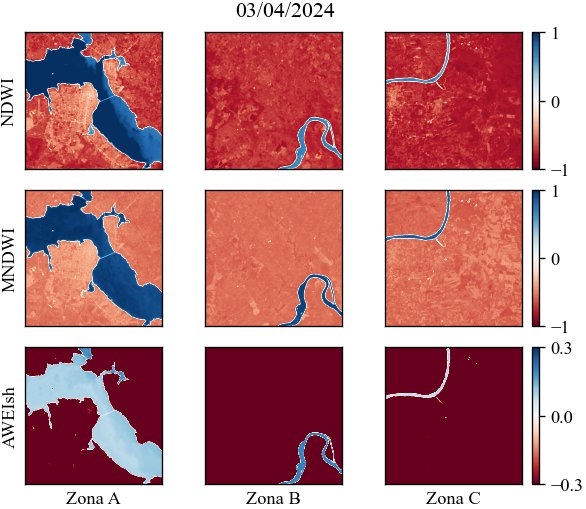

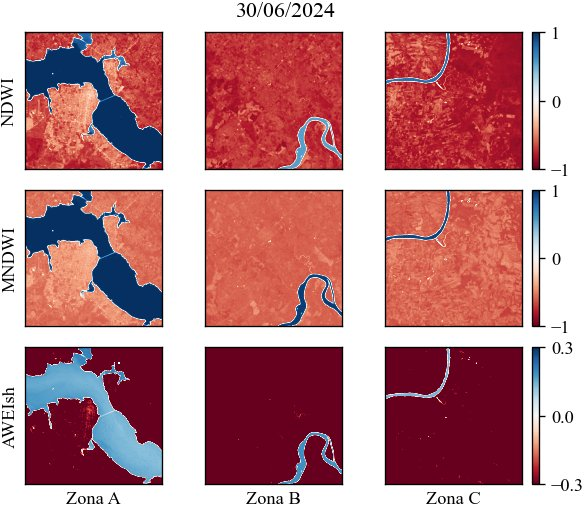

In [28]:
# Índices en las tres zonas: paleta divergente centrada en 0 (el umbral nominal), agua en azul.
# Filas: índices. Columnas: zonas.
ESCALA_IND = {"NDWI": 1.0, "MNDWI": 1.0, "AWEIsh": 0.3}
for f in FECHAS:
    fig, axs = plt.subplots(len(INDICES), len(ZONAS), figsize=(ancho(0.75), 4.25))
    for i, n in enumerate(INDICES):
        for j, (z, d) in enumerate(ZONAS.items()):
            ax = axs[i, j]
            im = ax.imshow(IND[f][z][n], cmap="RdBu", vmin=-ESCALA_IND[n], vmax=ESCALA_IND[n])
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(n)
            if i == len(INDICES) - 1:
                ax.set_xlabel(f"Zona {d['letra']}")
        barra = fig.colorbar(im, ax=axs[i, :], fraction=0.04, pad=0.02)
        barra.set_ticks([-ESCALA_IND[n], 0, ESCALA_IND[n]])
    fig.suptitle(f)
    guardar(fig, "indices_zonas" if f == FECHAS[0] else "")
    plt.show()

**Qué se observa.**

- **En el NDWI y el MNDWI el agua es azul intenso y la tierra roja,** en las tres zonas.
- **En el NDWI la zona urbana de Posadas se ve más clara que la vegetación** (−0,36 frente a −0,73 en las muestras).
- **En el MNDWI toda la tierra queda en valores parecidos** (−0,35 a −0,57) y el agua cerca de +0,9.
- **La confusión con la zona urbana que motivó el MNDWI no aparece en estas zonas:** la ciudad da negativo en los dos índices.
- **Los arroyos de la zona B casi no se distinguen del entorno.** En la zona C se ve la desembocadura del arroyo cerca de Garuhapé.

### Umbralización

Cada índice se umbraliza de dos formas, y se agrega como referencia la banda NIR sola:

- **Umbral fijo en 0:** el valor nominal de los tres índices.
- **Otsu** (notebooks 1 y 3 de la cátedra): elige el umbral que mejor separa el histograma en dos grupos. Se calcula por zona, índice y fecha, sobre los valores reales del índice (`threshold_otsu` de scikit-image, el mismo método que `cv2.THRESH_OTSU` pero sin pasar a 8 bits).
- **B5 con Otsu:** agua donde el NIR queda por debajo del umbral. Es el método más simple que sugiere la consigna.

In [29]:
METODOS_AGUA = {}
for n in INDICES:
    METODOS_AGUA[f"{n} > 0"] = (n, "fijo")
    METODOS_AGUA[f"{n} > Otsu"] = (n, "otsu")
METODOS_AGUA["B5 < Otsu"] = ("B5", "otsu")

UMBRALES, MASCARAS = {}, {}
for f in FECHAS:
    for z in ZONAS:
        for m, (n, tipo) in METODOS_AGUA.items():
            x = banda(RECORTES[f][z], 5) if n == "B5" else IND[f][z][n]
            u = 0.0 if tipo == "fijo" else threshold_otsu(x[np.isfinite(x)])
            UMBRALES[f, z, m] = u
            MASCARAS[f, z, m] = (x < u) if n == "B5" else (x > u)

pd.Series({k: v for k, v in UMBRALES.items() if "Otsu" in k[2]}).unstack([0, 1]).round(3)

03/04/2024                           30/06/2024  \
                  Paraná Uruguay–Chimiray Garuhapé     Paraná   
AWEIsh > Otsu     -0.223           -0.207   -0.539     -0.164   
B5 < Otsu          0.142            0.186    0.285      0.122   
MNDWI > Otsu       0.207            0.156    0.098      0.230   
NDWI > Otsu        0.139           -0.055   -0.129      0.176   

                                         
              Uruguay–Chimiray Garuhapé  
AWEIsh > Otsu           -0.189   -0.439  
B5 < Otsu                0.213    0.225  
MNDWI > Otsu             0.155    0.137  
NDWI > Otsu             -0.112   -0.035

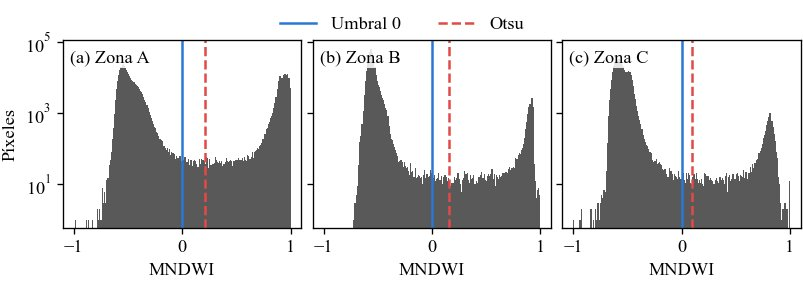

In [30]:
# Histogramas del MNDWI del 03/04 con los dos umbrales (eje vertical logarítmico: el agua es poca en B y C)
fig, axs = plt.subplots(1, len(ZONAS), figsize=(ancho(1.0), 2.4), sharey=True)
for ax, (z, d), letra in zip(axs, ZONAS.items(), "abc"):
    x = IND[FECHAS[0]][z]["MNDWI"]
    ax.hist(x[np.isfinite(x)], bins=200, range=(-1, 1), color="0.35", histtype="stepfilled")
    ax.axvline(0, color="#2a78d6", lw=1.5, label="Umbral 0")
    ax.axvline(UMBRALES[FECHAS[0], z, "MNDWI > Otsu"], color="#e34948", lw=1.5, ls="--", label="Otsu")
    ax.set_yscale("log")
    ax.set_xlabel("MNDWI")
    etiquetar(ax, letra, f"Zona {d['letra']}")
axs[0].set_ylabel("Píxeles")
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
guardar(fig, "histogramas_umbral")
plt.show()

**Qué se observa.**

- **Umbrales de Otsu.** Para el NDWI y el MNDWI quedan entre −0,13 y 0,23, en el valle del histograma. Para el AWEIsh en la zona C (−0,54 y −0,44) y para el NIR solo en las zonas B y C, Otsu corta **dentro de la tierra**.
- **Por qué falla.** Otsu busca dos grupos de tamaño parecido. Cuando el agua es apenas el 2 % o 3 % de la zona, la mejor partición es separar dos tipos de tierra, y la máscara marca como agua decenas de veces más superficie de la real.
- **Histogramas del MNDWI.** Son bimodales en las tres zonas, pero en B y C el pico del agua es unas 100 veces más bajo que el de la tierra. Entre los dos picos queda una meseta de unos 10 a 100 píxeles por intervalo: son los **píxeles mezcla** de las orillas y los cuerpos de agua chicos.

El histograma bimodal permite umbralizar, como señalaba el trabajo de 2025, pero el umbral automático solo es confiable si el agua ocupa una parte importante de la imagen.

### Coincidencia con `QA_PIXEL`

Cada máscara se compara con el bit de agua de `QA_PIXEL`, sobre los píxeles válidos. El porcentaje de coincidencia sobre todos los píxeles engaña cuando el agua es poca: en la zona B, con 3 % de agua, una máscara sin ningún píxel de agua coincidiría en un 97 %. Por eso se informan también la coincidencia **dentro del agua** y los dos tipos de desacuerdo:

- **Coincidencia total:** porcentaje de píxeles en que las dos máscaras dicen lo mismo.
- **Coincidencia en el agua:** de los píxeles que alguna de las dos marca como agua, porcentaje en que coinciden.
- **Agua de más:** píxeles que la máscara marca como agua y `QA_PIXEL` no, en porcentaje del agua de `QA_PIXEL`.
- **Agua de menos:** píxeles de agua de `QA_PIXEL` que la máscara no detecta, en el mismo porcentaje.

In [31]:
KM2_PIXEL = 30 * 30 / 1e6


def comparar_con_qa(mascara, qa):
    v = qa["valido"]
    a, b = mascara[v], qa["agua"][v]
    return {"Coincidencia total [%]": 100 * np.mean(a == b),
            "Coincidencia en el agua [%]": 100 * np.sum(a & b) / np.sum(a | b),
            "Agua de más [%]": 100 * np.sum(a & ~b) / b.sum(),
            "Agua de menos [%]": 100 * np.sum(~a & b) / b.sum(),
            "Área [km²]": a.sum() * KM2_PIXEL,
            "Área QA [km²]": b.sum() * KM2_PIXEL}


COINCIDENCIA = pd.DataFrame([
    {"Fecha": f, "Zona": z, "Método": m, **comparar_con_qa(MASCARAS[f, z, m], RECORTES[f][z]["qa"])}
    for f in FECHAS for z in ZONAS for m in METODOS_AGUA
])
COINCIDENCIA.pivot_table(index="Método", columns=["Fecha", "Zona"], values="Coincidencia en el agua [%]",
                         sort=False).round(1)

Fecha         03/04/2024                           30/06/2024  \
Zona              Paraná Uruguay–Chimiray Garuhapé     Paraná   
Método                                                          
NDWI > 0            99.7             99.0     98.7       99.6   
NDWI > Otsu         99.4             99.6     98.2       99.1   
MNDWI > 0           99.3             97.6     96.4       99.2   
MNDWI > Otsu        99.3             98.8     97.7       99.1   
AWEIsh > 0          99.6             99.5     99.0       99.5   
AWEIsh > Otsu       97.1             93.9      3.5       97.9   
B5 < Otsu           97.0             65.2      3.8       96.5   

Fecha                                    
Zona          Uruguay–Chimiray Garuhapé  
Método                                   
NDWI > 0                  97.5     97.5  
NDWI > Otsu               98.7     97.7  
MNDWI > 0                 98.7     96.0  
MNDWI > Otsu              98.4     97.0  
AWEIsh > 0                98.5     97.9  
AWEIsh > Otsu             87.3      4.1  
B5 < Otsu                 13.5      4.4

In [32]:
COINCIDENCIA.set_index(["Zona", "Fecha", "Método"]).sort_index(level=[0, 1], sort_remaining=False).round(2)

Coincidencia total [%]  \
Zona             Fecha      Método                                  
Garuhapé         03/04/2024 NDWI > 0                        99.98   
                            NDWI > Otsu                     99.97   
                            MNDWI > 0                       99.94   
                            MNDWI > Otsu                    99.96   
                            AWEIsh > 0                      99.98   
                            AWEIsh > Otsu                   51.52   
                            B5 < Otsu                       56.08   
                 30/06/2024 NDWI > 0                        99.95   
                            NDWI > Otsu                     99.96   
                            MNDWI > 0                       99.92   
                            MNDWI > Otsu                    99.95   
                            AWEIsh > 0                      99.96   
                            AWEIsh > Otsu                   57.78   
                            B5 < Otsu                       60.36   
Paraná           03/04/2024 NDWI > 0                        99.91   
                            NDWI > Otsu                     99.80   
                            MNDWI > 0                       99.75   
                            MNDWI > Otsu                    99.77   
                            AWEIsh > 0                      99.88   
                            AWEIsh > Otsu                   99.03   
                            B5 < Otsu                       98.99   
                 30/06/2024 NDWI > 0                        99.85   
                            NDWI > Otsu                     99.70   
                            MNDWI > 0                       99.73   
                            MNDWI > Otsu                    99.71   
                            AWEIsh > 0                      99.85   
                            AWEIsh > Otsu                   99.29   
                            B5 < Otsu                       98.80   
Uruguay–Chimiray 03/04/2024 NDWI > 0                        99.97   
                            NDWI > Otsu                     99.99   
                            MNDWI > 0                       99.92   
                            MNDWI > Otsu                    99.96   
                            AWEIsh > 0                      99.98   
                            AWEIsh > Otsu                   99.80   
                            B5 < Otsu                       98.33   
                 30/06/2024 NDWI > 0                        99.92   
                            NDWI > Otsu                     99.96   
                            MNDWI > 0                       99.96   
                            MNDWI > Otsu                    99.95   
                            AWEIsh > 0                      99.95   
                            AWEIsh > Otsu                   99.53   
                            B5 < Otsu                       79.29   

                                           Coincidencia en el agua [%]  \
Zona             Fecha      Método                                       
Garuhapé         03/04/2024 NDWI > 0                             98.71   
                            NDWI > Otsu                          98.20   
                            MNDWI > 0                            96.40   
                            MNDWI > Otsu                         97.68   
                            AWEIsh > 0                           99.01   
                            AWEIsh > Otsu                         3.45   
                            B5 < Otsu                             3.80   
                 30/06/2024 NDWI > 0                             97.51   
                            NDWI > Otsu                          97.71   
                            MNDWI > 0                            95.95   
                            MNDWI > Otsu                         97.03   
                            AWEIsh > 0      

**Qué se observa.**

- **Con los tres índices y umbral 0, o con NDWI y MNDWI y Otsu,** la coincidencia en el agua va de 96 % a 99,7 % en todas las zonas y fechas, y el área de agua difiere de la de `QA_PIXEL` en menos de 0,6 km².
- **El AWEIsh con Otsu y el NIR con Otsu fallan donde el agua es poca:** coincidencia en el agua de 3,5 % a 65 % en las zonas B y C.
- **La coincidencia alta no prueba que los métodos sean exactos.** Según el USGS, el bit de agua lo genera CFMask, una implementación del algoritmo Fmask (Zhu y Woodcock, 2012), cuyo test de agua usa umbrales sobre el NDVI y el NIR. `QA_PIXEL` es otro criterio espectral, parecido al de los índices, y favorece en particular a los que usan el NIR, como el NDWI.

### Dónde están los desacuerdos

Si los desacuerdos se concentran en la orilla, se deben a **píxeles mezcla**: píxeles de 30 m que cubren en parte agua y en parte tierra, y que cada criterio clasifica distinto. Se mide qué parte de los desacuerdos cae en una franja de un píxel a cada lado del borde del agua de `QA_PIXEL`. La franja se obtiene con una dilatación de 3 × 3 (una operación morfológica): los píxeles a un píxel o menos del agua, que además están a un píxel o menos de la tierra.

In [33]:
def dilatar(m):
    # Píxeles a un píxel o menos de m (vecindad de 8): dilatación con un elemento de 3 × 3
    p = np.pad(m, 1)
    filas, cols = m.shape
    return np.any([p[1 + dy:1 + dy + filas, 1 + dx:1 + dx + cols]
                   for dy in (-1, 0, 1) for dx in (-1, 0, 1)], axis=0)


CANDIDATOS = ["NDWI > 0", "NDWI > Otsu", "MNDWI > 0", "MNDWI > Otsu", "AWEIsh > 0"]
filas = []
for f in FECHAS:
    for z in ZONAS:
        q = RECORTES[f][z]["qa"]
        orilla = dilatar(q["agua"]) & dilatar(~q["agua"])
        for m in CANDIDATOS:
            a = MASCARAS[f, z, m] & q["valido"]
            de_mas, de_menos = a & ~q["agua"], ~a & q["agua"] & q["valido"]
            filas.append({"Fecha": f, "Zona": z, "Método": m,
                          "Píxeles de más": de_mas.sum(),
                          "De más en la orilla [%]": 100 * (de_mas & orilla).sum() / max(de_mas.sum(), 1),
                          "Píxeles de menos": de_menos.sum(),
                          "De menos en la orilla [%]": 100 * (de_menos & orilla).sum() / max(de_menos.sum(), 1)})
ORILLA = pd.DataFrame(filas).set_index(["Zona", "Fecha", "Método"]).sort_index(level=[0, 1], sort_remaining=False)
ORILLA.round(1)

Píxeles de más  \
Zona             Fecha      Método                         
Garuhapé         03/04/2024 NDWI > 0                   6   
                            NDWI > Otsu              137   
                            MNDWI > 0                275   
                            MNDWI > Otsu             147   
                            AWEIsh > 0                57   
                 30/06/2024 NDWI > 0                   9   
                            NDWI > Otsu               33   
                            MNDWI > 0                279   
                            MNDWI > Otsu             130   
                            AWEIsh > 0                65   
Paraná           03/04/2024 NDWI > 0                  81   
                            NDWI > Otsu                0   
                            MNDWI > 0                789   
                            MNDWI > Otsu             300   
                            AWEIsh > 0               238   
                 30/06/2024 NDWI > 0                  87   
                            NDWI > Otsu                0   
                            MNDWI > 0                673   
                            MNDWI > Otsu             198   
                            AWEIsh > 0               144   
Uruguay–Chimiray 03/04/2024 NDWI > 0                   1   
                            NDWI > Otsu                2   
                            MNDWI > 0                326   
                            MNDWI > Otsu             125   
                            AWEIsh > 0                52   
                 30/06/2024 NDWI > 0                   0   
                            NDWI > Otsu               10   
                            MNDWI > 0                122   
                            MNDWI > Otsu              24   
                            AWEIsh > 0                 6   

                                          De más en la orilla [%]  \
Zona             Fecha      Método                                  
Garuhapé         03/04/2024 NDWI > 0                         66.7   
                            NDWI > Otsu                      47.4   
                            MNDWI > 0                        85.5   
                            MNDWI > Otsu                     89.1   
                            AWEIsh > 0                       91.2   
                 30/06/2024 NDWI > 0                         33.3   
                            NDWI > Otsu                      27.3   
                            MNDWI > 0                        75.3   
                            MNDWI > Otsu                     77.7   
                            AWEIsh > 0                       75.4   
Paraná           03/04/2024 NDWI > 0                         40.7   
                            NDWI > Otsu                       0.0   
                            MNDWI > 0                        91.9   
                            MNDWI > Otsu                     96.0   
                            AWEIsh > 0                       98.3   
                 30/06/2024 NDWI > 0                         20.7   
                            NDWI > Otsu                       0.0   
                            MNDWI > 0                        91.5   
                            MNDWI > Otsu                     93.4   
                            AWEIsh > 0                       88.9   
Uruguay–Chimiray 03/04/2024 NDWI > 0                          0.0   
                            NDWI > Otsu                       0.0   
                            MNDWI > 0                        95.7   
                            MNDWI > Otsu                     96.0   
                            AWEIsh > 0                       98.1   
                 30/06/2024 NDWI > 0                          0.0   
                            NDWI > Otsu                      20.0   
                            MNDWI > 0                        86.9   
                            MNDWI > Otsu           

**Qué se observa.**

- **Los desacuerdos están casi todos en la orilla:** con el MNDWI, entre el 75 % y el 96 % del agua de más y entre el 79 % y el 100 % del agua de menos caen en la franja del borde. Son píxeles mezcla que cada criterio asigna distinto, no errores en el medio del agua o de la tierra.
- **El MNDWI con umbral 0 es el más inclusivo:** en la orilla marca como agua más píxeles que `QA_PIXEL` (122 a 789) y deja afuera muy pocos en las zonas rurales (10 a 73, contra 93 a 358 del NDWI). Para detectar cuerpos de agua chicos, que son casi todo borde, conviene un criterio que incluya los píxeles mezcla.
- **No hay indicios de sombras confundidas con agua en junio:** con el MNDWI, el agua de más de la zona C pasa de 275 a 279 píxeles, y con el NDWI de 6 a 9, a pesar del sol más bajo. Al ser cocientes, los índices compensan la menor iluminación de las laderas.

### Método elegido

Se usa el **MNDWI con umbral fijo en 0** para las secciones siguientes:

- **Es el índice que más separa el agua** de todas las coberturas (F de la peor pareja entre 92,8 y 242,9).
- **Su coincidencia con `QA_PIXEL` es comparable a la de los demás métodos** (96 % a 99,3 % en el agua), y sus desacuerdos son píxeles mezcla de la orilla.
- **Es el más inclusivo con los píxeles mezcla,** lo que favorece a los arroyos y tajamares.
- **El umbral fijo aplica el mismo criterio en todas las zonas y fechas,** que es lo que necesita la comparación entre fechas. Otsu cambia con el contenido de cada recorte y se vuelve inestable cuando hay poca agua.

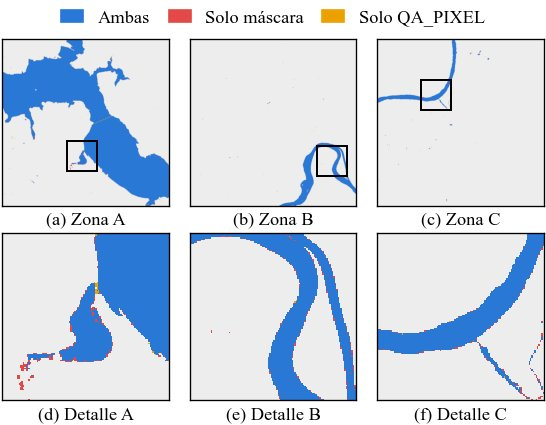

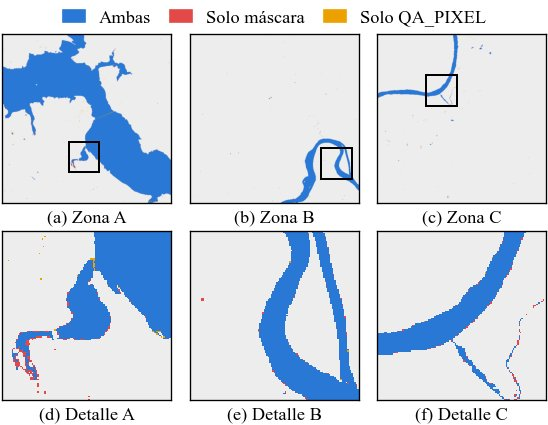

In [34]:
# Mapa de discrepancias con QA_PIXEL para el método elegido: zonas completas y un detalle
# de 120 × 120 px (3,6 km) donde más se concentran los desacuerdos
METODO_AGUA = "MNDWI > 0"
CATEGORIAS = {"Ambas": "#2a78d6", "Solo máscara": "#e34948", "Solo QA_PIXEL": "#eda100"}
FONDO = np.array([0.93, 0.93, 0.93])
LADO_DETALLE = 120


def imagen_discrepancias(f, z, metodo=METODO_AGUA):
    q = RECORTES[f][z]["qa"]
    a = MASCARAS[f, z, metodo] & q["valido"]
    img = np.tile(FONDO, (*a.shape, 1))
    for cat, m in zip(CATEGORIAS, [a & q["agua"], a & ~q["agua"], ~a & q["agua"] & q["valido"]]):
        img[m] = matplotlib.colors.to_rgb(CATEGORIAS[cat])
    return img, (a ^ q["agua"]) & q["valido"]


def ventana_detalle(desacuerdo, lado=LADO_DETALLE):
    # Cuadrado de `lado` píxeles con más desacuerdos (suma en una ventana deslizante)
    h = lado // 2
    suma = cv2.boxFilter(desacuerdo.astype(np.float32), -1, (lado, lado), normalize=False)
    suma[:h], suma[-h:], suma[:, :h], suma[:, -h:] = 0, 0, 0, 0
    fi, co = np.unravel_index(np.argmax(suma), suma.shape)
    return np.s_[fi - h:fi + h, co - h:co + h]


for f in FECHAS:
    fig, axs = plt.subplots(2, len(ZONAS), figsize=(ancho(0.7), 3.6))
    for j, (z, d) in enumerate(ZONAS.items()):
        img, desacuerdo = imagen_discrepancias(f, z)
        v = ventana_detalle(desacuerdo)
        axs[0, j].imshow(img)
        axs[0, j].add_patch(Rectangle((v[1].start - 0.5, v[0].start - 0.5), LADO_DETALLE, LADO_DETALLE,
                                      fill=False, ec="black", lw=1.2))
        axs[1, j].imshow(img[v], interpolation="nearest")
        axs[0, j].set_xlabel(f"({'abc'[j]}) Zona {d['letra']}")
        axs[1, j].set_xlabel(f"({'def'[j]}) Detalle {d['letra']}")
        for ax in axs[:, j]:
            ax.set_xticks([])
            ax.set_yticks([])
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.91))
    fig.legend([Rectangle((0, 0), 1, 1, color=col) for col in CATEGORIAS.values()], CATEGORIAS,
               loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
           handlelength=1.2, columnspacing=1.0)
    guardar(fig, "discrepancias_qa" if f == FECHAS[0] else "")
    plt.show()

**Qué se observa.** A la escala de la zona completa, las dos máscaras se superponen casi por completo. En los detalles, los desacuerdos forman líneas de uno o dos píxeles en las orillas y se concentran en los cuerpos de agua más angostos:

- **Zona A:** un arroyo que desemboca en una bahía del embalse aparece como agua solo en la máscara del MNDWI.
- **Zona B:** solo píxeles sueltos en las orillas del Uruguay.
- **Zona C:** el detalle cae sobre la desembocadura del arroyo cerca de Garuhapé. El tramo ancho coincide, y aguas arriba el agua queda cortada en tramos, alternando píxeles de las dos categorías.

Es el límite de los 30 m que se analiza en la sección siguiente.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Índices | NDWI, MNDWI y AWEIsh | Usan las bandas más separables; el AWEIsh usa además las bandas de la consigna | Solo la banda NIR | Su peor F (14,5) es mucho menor que la del MNDWI (92,8 a 242,9) | Métrica (Fisher) |
| Validación | Coincidencia con `QA_PIXEL`, total y dentro del agua, más agua de más y de menos | Con 3 % de agua, la coincidencia total es engañosa: una máscara vacía coincidiría en un 97 % | Solo la coincidencia total | No distingue una buena máscara de una vacía | — |
| Umbral | Fijo en 0 | Mismo criterio en todas las zonas y fechas | Otsu por recorte | Con 2 % a 3 % de agua corta dentro de la tierra (AWEIsh y NIR en las zonas B y C) | Métrica (coincidencia) |
| Método de detección | MNDWI > 0 | Máxima separabilidad; coincidencia en el agua de 96 % a 99,3 %; el más inclusivo en la orilla | NDWI > 0 | Coincide algo más con `QA_PIXEL`, que también usa el NIR, pero deja afuera más agua de orilla en las zonas rurales | Métrica (Fisher, coincidencia y orilla) |
| Detalle del mapa de discrepancias | Ventana de 120 × 120 px con más desacuerdos | A escala de zona completa los desacuerdos no se ven | Solo las zonas completas | Las líneas de un píxel desaparecen al reducir la imagen | Visual |

## 6. Agua grande y agua chica

### Recorridos de OpenStreetMap

`QA_PIXEL` sirve de referencia para los ríos, pero no para los arroyos: es otra clasificación a 30 m, con el mismo límite de resolución. Como referencia independiente se usan los recorridos de los cursos de agua de OpenStreetMap, mapeados sobre imágenes de mayor resolución (archivo `datos/arroyos_osm.csv`; si falta, por ejemplo en Colab, el notebook lo descarga con la API Overpass). Tienen dos limitaciones: su posición puede tener errores de decenas de metros, y un arroyo mapeado puede estar seco o cubierto por el monte en la fecha de la imagen.

**Criterio de detección.** Un punto del recorrido se considera detectado si hay agua según el MNDWI en su vecindad de 3 × 3 píxeles. Ese margen de un píxel absorbe el error de posición del recorrido y el de la cuadrícula de 30 m.

**Cauce principal.** Los tramos de los arroyos que entran en el Paraná o en el Uruguay no son agua chica. El cauce principal se separa con una **apertura morfológica** (operación de la unidad 3): una erosión seguida de una dilatación, con un elemento circular de 9 píxeles de diámetro. Elimina todo lo que mide menos de unos 270 m de ancho y deja solo el agua ancha.

In [35]:
ARCHIVO_OSM = DIR_DATOS / "arroyos_osm.csv"


def preparar_osm():
    # Recorridos de OSM: si falta el archivo (por ejemplo, en Colab), se descargan con la API Overpass
    if ARCHIVO_OSM.exists():
        return
    import csv
    import json
    import urllib.parse
    import urllib.request
    cajas = []   # (sur, oeste, norte, este) de cada zona, con 1 km de margen
    for d in ZONAS.values():
        dlat = (d["lado"] / 2 + 1) / 111.32
        dlon = (d["lado"] / 2 + 1) / (111.32 * math.cos(math.radians(d["lat"])))
        cajas.append((d["lat"] - dlat, d["lon"] - dlon, d["lat"] + dlat, d["lon"] + dlon))
    consulta = ("[out:json][timeout:90];("
                + "".join(f'way["waterway"~"^(river|stream)$"]({s},{o},{n},{e});' for s, o, n, e in cajas)
                + ");out geom tags;")
    pedido = urllib.request.Request("https://overpass-api.de/api/interpreter",
                                    data=urllib.parse.urlencode({"data": consulta}).encode(),
                                    headers={"User-Agent": "FDPI-lab1-UNaM (uso academico)"})
    vias = json.loads(urllib.request.urlopen(pedido, timeout=180).read())["elements"]
    adentro = lambda la, lo: any(s <= la <= n and o <= lo <= e for s, o, n, e in cajas)
    with open(ARCHIVO_OSM, "w", encoding="utf-8", newline="\n") as f:
        f.write("# Cursos de agua (waterway = river o stream) dentro de las zonas de estudio, con 1 km de margen.\n")
        f.write("# Datos (c) colaboradores de OpenStreetMap, licencia ODbL (https://www.openstreetmap.org/copyright).\n")
        f.write(f"# Descargados el {pd.Timestamp.today():%Y-%m-%d} con la API Overpass. "
                "Cada tramo sigue el sentido del flujo: su último punto es el más bajo.\n")
        w = csv.writer(f, lineterminator="\n")
        w.writerow(["tramo", "nombre", "tipo", "lat", "lon"])
        for v in vias:
            corrida, afuera = 0, True
            for p in v.get("geometry", []):
                if adentro(p["lat"], p["lon"]):
                    corrida, afuera = corrida + afuera, False
                    w.writerow([f"{v['id']}-{corrida}", v["tags"].get("name", ""), v["tags"]["waterway"],
                                f"{p['lat']:.6f}", f"{p['lon']:.6f}"])
                else:
                    afuera = True


preparar_osm()
OSM = pd.read_csv(ARCHIVO_OSM, comment="#").fillna({"nombre": ""})
ELEMENTO = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))


def agua_ancha(mascara):
    # Apertura morfológica: queda solo el agua de más de unos 270 m de ancho
    return cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_OPEN, ELEMENTO).astype(bool)


def recorridos(fecha, zona):
    # Tramos de OSM en coordenadas (fila, col) del recorte de la zona, densificados cada 0,5 px
    e, v = ESCENAS[fecha], RECORTES[fecha][zona]["ventana"]
    lado = v[0].stop - v[0].start
    tramos = {}
    for tramo, g in OSM.groupby("tramo", sort=False):
        xy = np.array([latlon_a_utm(la, lo) for la, lo in zip(g["lat"], g["lon"])])
        p = np.c_[(e["y0"] - xy[:, 1]) / e["celda"] - v[0].start, (xy[:, 0] - e["x0"]) / e["celda"] - v[1].start]
        densos = [p[:1]]
        for a, b in zip(p[:-1], p[1:]):
            n = max(1, int(np.ceil(np.hypot(*(b - a)) / 0.5)))
            densos.append(a + (b - a) * np.arange(1, n + 1)[:, None] / n)
        p = np.concatenate(densos)
        adentro = ((p > -0.5) & (p < lado - 0.5)).all(axis=1)
        if adentro.sum() > 1:
            tramos[tramo] = {"nombre": g["nombre"].iloc[0], "tipo": g["tipo"].iloc[0],
                             "puntos": p[adentro], "indices": np.round(p[adentro]).astype(int)}
    return tramos


def en_puntos(img, tramo):
    fi, co = tramo["indices"].T
    return img[fi, co]


RECORRIDOS = {(f, z): recorridos(f, z) for f in FECHAS for z in ZONAS}
pd.DataFrame([{"Zona": z, "Tramos": len(t), "Largo [km]": sum(len(x["puntos"]) for x in t.values()) * 0.5 * 30 / 1000}
              for (f, z), t in RECORRIDOS.items() if f == FECHAS[0]]).round(1)

,Zona,Tramos,Largo [km]
0,Paraná,389,238.9
1,Uruguay–Chimiray,140,255.2
2,Garuhapé,116,226.5


### Detección a lo largo de los arroyos

In [36]:
RIOS = {"Río Paraná", "Río Uruguay"}
ARROYOS = {"Paraná": ["Arroyo Zaimán", "Arroyo Mártires"],
           "Uruguay–Chimiray": ["Arroyo Tunas", "Arroyo Chimiray", "Arroyo Concepción"],
           "Garuhapé": ["Arroyo Garuhapé", "Arroyo Garuhapé-Mí", "Arroyo Tres de Mayo", "Arroyo Moreno"]}

filas = []
for f in FECHAS:
    for z in ZONAS:
        mndwi = IND[f][z]["MNDWI"]
        agua = dilatar(mndwi > 0)
        cauce = dilatar(agua_ancha(mndwi > 0))
        qa = dilatar(RECORTES[f][z]["qa"]["agua"])
        ndvi = dif_normalizada(RECORTES[f][z]["refl"], 5, 4)
        grupos = {n: [t for t in RECORRIDOS[f, z].values() if t["nombre"] == n] for n in ARROYOS[z]}
        grupos["Todos los arroyos de la zona"] = [t for t in RECORRIDOS[f, z].values() if t["nombre"] not in RIOS]
        for nombre, tramos in grupos.items():
            fuera = np.concatenate([~en_puntos(cauce, t) for t in tramos])
            def valores(img):
                return np.concatenate([en_puntos(img, t) for t in tramos])[fuera]
            filas.append({"Zona": z, "Arroyo": nombre, "Fecha": f,
                          "Largo [km]": fuera.sum() * 0.5 * 30 / 1000,
                          "Detectado MNDWI [%]": 100 * valores(agua).mean(),
                          "Agua según QA [%]": 100 * valores(qa).mean(),
                          "NDVI mediano": np.nanmedian(valores(ndvi))})
DETECCION = pd.DataFrame(filas)
DETECCION.pivot_table(index=["Zona", "Arroyo"], columns="Fecha", sort=False,
                      values=["Largo [km]", "Detectado MNDWI [%]", "Agua según QA [%]", "NDVI mediano"]).round(2)

Largo [km]             \
Fecha                                         03/04/2024 30/06/2024   
Zona             Arroyo                                               
Paraná           Arroyo Zaimán                     11.19      10.76   
                 Arroyo Mártires                    9.80       9.66   
                 Todos los arroyos de la zona     142.10     141.28   
Uruguay–Chimiray Todos los arroyos de la zona     228.34     228.28   
                 Arroyo Tunas                      28.84      28.84   
                 Arroyo Chimiray                   43.58      43.58   
                 Arroyo Concepción                 13.40      13.34   
Garuhapé         Todos los arroyos de la zona     207.42     207.30   
                 Arroyo Garuhapé                   45.54      45.56   
                 Arroyo Garuhapé-Mí                18.80      18.80   
                 Arroyo Tres de Mayo               18.30      18.30   
                 Arroyo Moreno                      7.96       7.96   

                                              Detectado MNDWI [%]             \
Fecha                                                  03/04/2024 30/06/2024   
Zona             Arroyo                                                        
Paraná           Arroyo Zaimán                               9.65      16.60   
                 Arroyo Mártires                             7.96       4.97   
                 Todos los arroyos de la zona                3.16       3.79   
Uruguay–Chimiray Todos los arroyos de la zona                0.45       1.13   
                 Arroyo Tunas                                2.29       7.18   
                 Arroyo Chimiray                             0.00       0.62   
                 Arroyo Concepción                           0.78       0.67   
Garuhapé         Todos los arroyos de la zona                2.43       3.63   
                 Arroyo Garuhapé                             9.75      13.30   
                 Arroyo Garuhapé-Mí                          0.00       0.00   
                 Arroyo Tres de Mayo                         0.57       3.93   
                 Arroyo Moreno                               0.00       0.00   

                                              Agua según QA [%]             \
Fecha                                                03/04/2024 30/06/2024   
Zona             Arroyo                                                      
Paraná           Arroyo Zaimán                             8.98      11.16   
                 Arroyo Mártires                           7.96       4.81   
                 Todos los arroyos de la zona              2.90       2.89   
Uruguay–Chimiray Todos los arroyos de la zona              0.29       1.76   
                 Arroyo Tunas                              1.56      10.71   
                 Arroyo Chimiray                           0.00       1.24   
                 Arroyo Concepción                         0.78       0.67   
Garuhapé         Todos los arroyos de la zona              1.67       2.63   
                 Arroyo Garuhapé                           6.75      10.93   
                 Arroyo Garuhapé-Mí                        0.00       0.00   
                 Arroyo Tres de Mayo                       0.57       1.89   
                 Arroyo Moreno                             0.00       0.00   

                                              NDVI mediano             
Fecha                                           03/04/2024 30/06/2024  
Zona             Arroyo                                                
Paraná           Arroyo Zaimán                        0.84       0.80  
                 Arroyo Mártires                      0.82       0.78  
                 Todos los arroyos de la zona         0.79       0.75  
Uruguay–Chimiray Todos los arroyos de la zona         0.82       0.76  
                 Arroyo Tunas                         0.78       0.64  
                 Arroyo Chimiray

**Qué se observa.**

- **Las zonas tienen entre 230 y 255 km de recorridos mapeados.**
- **Sin contar el cauce principal, el MNDWI detecta entre el 0,5 % y el 3,8 % de los arroyos de cada zona.** Los arroyos con alguna detección son los que tienen un tramo bajo ancho o un brazo de embalse:
  - Garuhapé: 9,8 % y 13,3 %.
  - Zaimán, que forma una bahía del Paraná: 9,7 % y 16,6 %.
  - Tunas: 2,3 % y 7,2 %.
  - Chimiray: 0 % y 0,6 %, igual que los de las cabeceras (Garuhapé-Mí y Moreno).
- **`QA_PIXEL` da porcentajes del mismo orden:** tiene el mismo límite de resolución.
- **El NDVI mediano sobre los recorridos va de 0,75 a 0,87:** son valores de vegetación densa (la clase vegetación da 0,77 a 0,81). Para el satélite, el píxel del arroyo es casi todo monte. Esto confirma la hipótesis de la **selva en galería**: el monte ribereño cubre el cauce angosto.
- **En junio se detecta más en casi todos los arroyos,** y baja el NDVI sobre sus recorridos (en el Tunas, de 0,78 a 0,64). Puede deberse a que la vegetación ribereña pierde hojas en invierno o a un mayor caudal; con dos fechas no se pueden separar las dos causas.

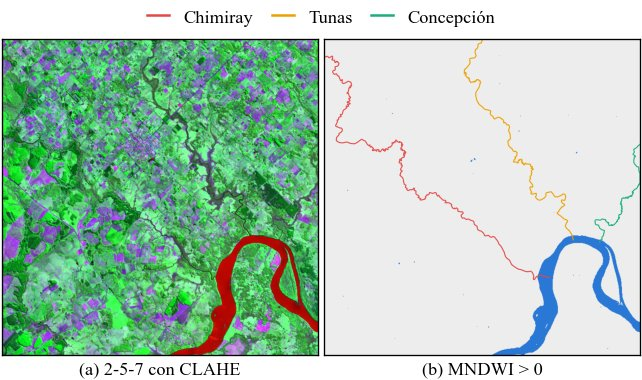

In [37]:
# Arroyos de la zona B: composición de la consigna con CLAHE, y máscara del MNDWI con los recorridos de OSM
COLORES_ARROYO = {"Arroyo Chimiray": "#e34948", "Arroyo Tunas": "#eda100", "Arroyo Concepción": "#1baf7a"}
f, z = FECHAS[0], "Uruguay–Chimiray"
mascara = np.tile(FONDO, (*IND[f][z]["MNDWI"].shape, 1))
mascara[IND[f][z]["MNDWI"] > 0] = matplotlib.colors.to_rgb("#2a78d6")
fig, axs = plt.subplots(1, 2, figsize=(ancho(0.8), ancho(0.8) / 2 + 0.55))
for ax, img, rotulo, letra in zip(axs, [componer(f, z, ORDEN_CONSIGNA, "CLAHE"), mascara],
                                  [f"{ORDEN_CONSIGNA} con CLAHE", "MNDWI > 0"], "ab"):
    mostrar_img(ax, img, rotulo, letra)
    for t in RECORRIDOS[f, z].values():
        if t["nombre"] in COLORES_ARROYO and letra == "b":
            ax.plot(t["puntos"][:, 1], t["puntos"][:, 0], color=COLORES_ARROYO[t["nombre"]], lw=0.7, alpha=0.9)
    ax.set_xlim(-0.5, mascara.shape[1] - 0.5)
    ax.set_ylim(mascara.shape[0] - 0.5, -0.5)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.91))
fig.legend([plt.Line2D([], [], color=c, lw=1.5) for c in COLORES_ARROYO.values()],
           [n.replace("Arroyo ", "") for n in COLORES_ARROYO], loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
           handlelength=1.2, columnspacing=1.0)
guardar(fig, "arroyos_zona_b")
plt.show()

**Qué se observa.** En la composición con CLAHE, el Tunas y el Chimiray se ven como corredores oscuros que siguen los recorridos de OpenStreetMap. Esto también confirma que los recorridos están bien ubicados. El del Tunas es más marcado, violáceo, y el del Chimiray es verde oscuro, como el monte. En la máscara del MNDWI, en cambio, no aparece agua a lo largo de ninguno de los dos, salvo junto al Uruguay. Que un arroyo **se vea** no significa que se **detecte como agua**: lo que se ve es su corredor.

### Perfiles longitudinales

MNDWI a lo largo del recorrido de tres arroyos, desde su desembocadura hacia arriba. En cada punto se toma el máximo de la vecindad de 3 × 3, con el mismo margen del criterio de detección. Los puntos que caen en el cauce principal no se grafican.

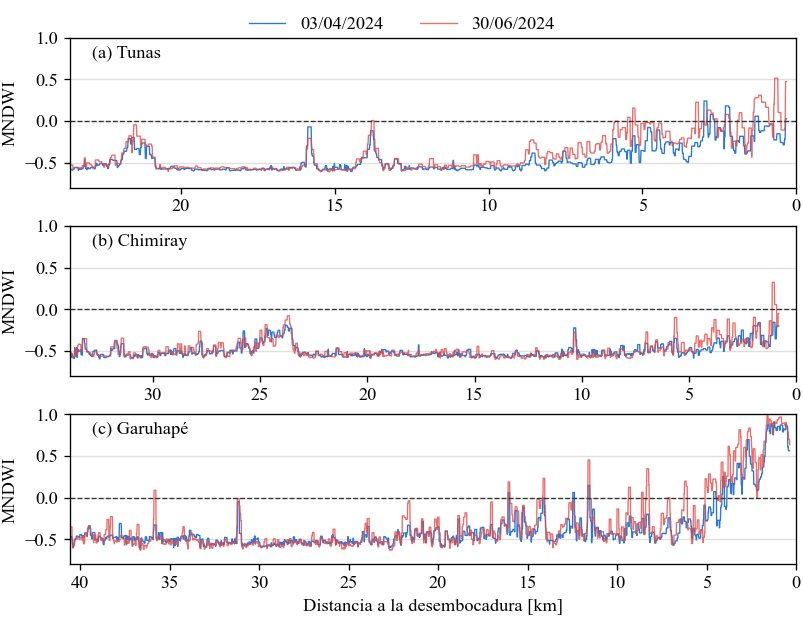

In [38]:
def mayor_tramo(f, z, nombre):
    return max((t for t in RECORRIDOS[f, z].values() if t["nombre"] == nombre), key=lambda t: len(t["puntos"]))


def maximo_3x3(img):
    p = np.pad(img, 1, constant_values=np.nan)
    filas, cols = img.shape
    return np.nanmax([p[1 + dy:1 + dy + filas, 1 + dx:1 + dx + cols] for dy in (-1, 0, 1) for dx in (-1, 0, 1)], axis=0)


def distancia_a_la_desembocadura(t):
    # km desde cada punto hasta el último punto del tramo (el más bajo), siguiendo el recorrido
    paso = np.r_[0, np.hypot(*np.diff(t["puntos"], axis=0).T)] * 30 / 1000
    return paso.sum() - np.cumsum(paso)


LONGITUDINALES = [("Uruguay–Chimiray", "Arroyo Tunas"), ("Uruguay–Chimiray", "Arroyo Chimiray"),
                  ("Garuhapé", "Arroyo Garuhapé")]
ESTILO_FECHA = {FECHAS[0]: dict(color="#2a78d6", lw=0.8), FECHAS[1]: dict(color="#e34948", lw=0.8, alpha=0.8)}
fig, axs = plt.subplots(len(LONGITUDINALES), 1, figsize=(ancho(1.0), 5.2), sharey=True)
for ax, (z, nombre), letra in zip(axs, LONGITUDINALES, "abc"):
    for f in FECHAS:
        t = mayor_tramo(f, z, nombre)
        dist = distancia_a_la_desembocadura(t)
        valor = en_puntos(maximo_3x3(IND[f][z]["MNDWI"]), t)
        valor[en_puntos(dilatar(agua_ancha(IND[f][z]["MNDWI"] > 0)), t)] = np.nan
        ax.plot(dist, valor, label=f, **ESTILO_FECHA[f])
    ax.axhline(0, color="0.2", lw=0.8, ls="--")
    ax.set_xlim(dist.max(), 0)
    ax.set_ylim(-0.8, 1)
    ax.set_ylabel("MNDWI")
    ax.grid(axis="y")
    etiquetar(ax, letra, nombre.replace("Arroyo ", ""))
axs[-1].set_xlabel("Distancia a la desembocadura [km]")
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
guardar(fig, "perfiles_longitudinales")
plt.show()

**Qué se observa.**

- **Garuhapé:** el MNDWI supera 0 en forma continua en los últimos 3,5 km y de manera intermitente hasta unos 16 km. Más arriba se queda en −0,5, el valor de la vegetación.
- **Tunas:** en los últimos 8 km el MNDWI sube hacia 0 sin superarlo de forma sostenida. En junio está más cerca, y lo cruza en algunos tramos.
- **Chimiray:** se queda en −0,5 casi todo el recorrido. Solo en el último kilómetro se acerca a 0.

La diferencia entre el Tunas y el Chimiray que se ve en la imagen se refleja en el índice: el Tunas deja una señal de agua mezclada en su tramo bajo, y el Chimiray no.

### Perfiles transversales

MNDWI a lo largo de una línea perpendicular al recorrido, interpolado cada 1/4 de píxel. El ancho detectado es el tramo continuo más largo con MNDWI > 0. El Paraná se corta en su sección más angosta dentro de la zona, entre los perfiles que cruzan un solo tramo de agua (sin islas ni el puente), y el Uruguay cerca del punto más alejado de sus orillas; los arroyos, a una distancia fija de su desembocadura.

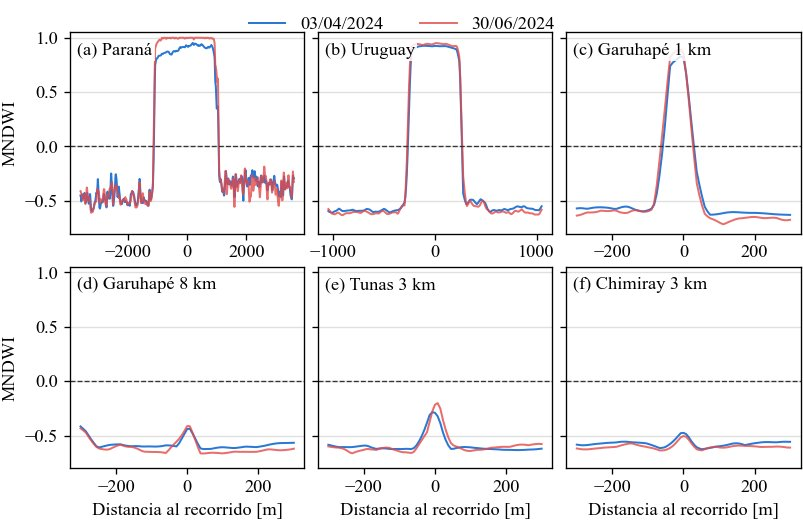

,Fecha,03/04/2024,30/06/2024
Perfil,Curso,,
(a),Río Paraná,2182.5,2205.0
(b),Río Uruguay,532.5,540.0
(c),Arroyo Garuhapé,82.5,90.0
(d),Arroyo Garuhapé,0.0,0.0
(e),Arroyo Tunas,0.0,0.0
(f),Arroyo Chimiray,0.0,0.0


In [39]:
def perfil_transversal(img, t, k, mitad_px, paso=0.25):
    # Perfil perpendicular al tramo t en su punto k; devuelve la distancia en metros y los valores
    p = t["puntos"]
    a, b = p[max(k - 6, 0)], p[min(k + 6, len(p) - 1)]
    tangente = (b - a) / np.linalg.norm(b - a)
    normal = np.array([-tangente[1], tangente[0]])
    s = np.arange(-mitad_px, mitad_px + paso / 2, paso)
    q = (p[k] + s[:, None] * normal).astype(np.float32)
    valores = cv2.remap(img.astype(np.float32), q[None, :, 1], q[None, :, 0], cv2.INTER_LINEAR)[0]
    return s * 30, valores


def ancho_continuo(s, valores):
    # Largo del tramo continuo más largo con MNDWI > 0 (en metros)
    mayor = actual = 0
    for v in valores > 0:
        actual = actual + 1 if v else 0
        mayor = max(mayor, actual)
    return mayor * (s[1] - s[0])


def seccion_mas_angosta(img, t, mitad, paso_puntos=10):
    # Punto del tramo donde el agua es más angosta, entre los perfiles que caben en el recorte y que
    # cruzan un solo tramo de agua (así se descartan los que pasan por islas o por el puente)
    lado = img.shape[0]
    mejor, k_mejor = np.inf, None
    for k in range(6, len(t["puntos"]) - 6, paso_puntos):
        a, b = t["puntos"][k - 6], t["puntos"][k + 6]
        normal = np.array([-(b - a)[1], (b - a)[0]]) / np.linalg.norm(b - a)
        extremos = t["puntos"][k] + np.array([[-mitad], [mitad]]) * normal
        if ((extremos < 0) | (extremos > lado - 1)).any():
            continue
        s, valores = perfil_transversal(img, t, k, mitad)
        tramos_de_agua = np.sum(np.diff((valores > 0).astype(int)) == 1) + int(valores[0] > 0)
        if tramos_de_agua == 1 and 0 < ancho_continuo(s, valores) < mejor:
            mejor, k_mejor = ancho_continuo(s, valores), k
    return k_mejor


def punto_mas_cercano(t, fila, col):
    return int(np.argmin(np.hypot(t["puntos"][:, 0] - fila, t["puntos"][:, 1] - col)))


def punto_a_distancia(t, km):
    return int(np.argmin(np.abs(distancia_a_la_desembocadura(t) - km)))


TRANSVERSALES = [  # (zona, nombre, cómo ubicar el punto, media longitud del perfil en px)
    ("Paraná", "Río Paraná", ("angosta",), 120),
    ("Uruguay–Chimiray", "Río Uruguay", ("cerca", 579, 469), 35),
    ("Garuhapé", "Arroyo Garuhapé", ("km", 1.0), 10),
    ("Garuhapé", "Arroyo Garuhapé", ("km", 8.0), 10),
    ("Uruguay–Chimiray", "Arroyo Tunas", ("km", 3.0), 10),
    ("Uruguay–Chimiray", "Arroyo Chimiray", ("km", 3.0), 10),
]
fig, axs = plt.subplots(2, 3, figsize=(ancho(1.0), 4.4), sharey=True)
filas = []
for ax, (z, nombre, ubicacion, mitad), letra in zip(axs.flat, TRANSVERSALES, "abcdef"):
    for f in FECHAS:
        t = mayor_tramo(f, z, nombre)
        if ubicacion[0] == "angosta":
            k = seccion_mas_angosta(IND[FECHAS[0]][z]["MNDWI"], mayor_tramo(FECHAS[0], z, nombre), mitad)
        elif ubicacion[0] == "cerca":
            k = punto_mas_cercano(t, *ubicacion[1:])
        else:
            k = punto_a_distancia(t, ubicacion[1])
        s, valores = perfil_transversal(IND[f][z]["MNDWI"], t, k, mitad)
        ancho_m = ancho_continuo(s, valores)
        ax.plot(s, valores, label=f, **{**ESTILO_FECHA[f], "lw": 1.2})
        filas.append({"Perfil": f"({letra})", "Curso": nombre, "Fecha": f, "Ancho detectado [m]": ancho_m})
    ax.axhline(0, color="0.2", lw=0.8, ls="--")
    ax.set_ylim(-0.8, 1.05)
    ax.grid(axis="y")
    sitio = f"{ubicacion[1]:.0f} km" if ubicacion[0] == "km" else ""
    etiquetar(ax, letra, f"{nombre.replace('Arroyo ', '').replace('Río ', '')} {sitio}".strip())
for ax in axs[:, 0]:
    ax.set_ylabel("MNDWI")
for ax in axs[1]:
    ax.set_xlabel("Distancia al recorrido [m]")
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
guardar(fig, "perfiles_transversales")
plt.show()
pd.DataFrame(filas).pivot_table(index=["Perfil", "Curso"], columns="Fecha", values="Ancho detectado [m]")

**Qué se observa.**

- **Paraná y Uruguay:** el perfil pasa de −0,6 a +0,9 en uno o dos píxeles. El ancho detectado es de unos 2,2 km para el Paraná, en su sección más angosta de la zona, y de unos 530 m para el Uruguay.
- **Garuhapé a 1 km de la desembocadura:** sigue siendo un escalón nítido de unos 80 a 90 m, es decir, 3 píxeles.
- **Garuhapé a 8 km, Tunas y Chimiray a 3 km:** el escalón se convierte en una pequeña subida, hasta −0,45 en el Garuhapé y el Chimiray y hasta −0,2 en el Tunas, que no llega al umbral. El agua sigue ahí, pero ocupa una fracción del píxel de 30 m y el resto es monte: es un **píxel mezcla** que se clasifica como vegetación.

### Sensibilidad al umbral

Un píxel de agua en medio del río tiene MNDWI cercano a 1 y no cambia de clase si el umbral se mueve un poco; un píxel mezcla de la orilla o de un arroyo angosto queda cerca de 0 y sí cambia. Se mueve el umbral entre −0,3 y 0,3 y se mide:

- **(a)** el área de agua relativa a la del umbral 0 (en escala logarítmica), separando el agua ancha (la que queda después de la apertura, con un margen de 2 píxeles) del resto, y
- **(b)** el porcentaje detectado del recorrido de tres arroyos.

Zona A, ancha: área relativa entre 0.99 y 1.01
Zona A, resto: área relativa entre 0.65 y 7.51
Zona B, ancha: área relativa entre 0.98 y 1.03
Zona B, resto: área relativa entre 0.88 y 1.36
Zona C, ancha: área relativa entre 0.96 y 1.05
Zona C, resto: área relativa entre 0.64 y 2.26


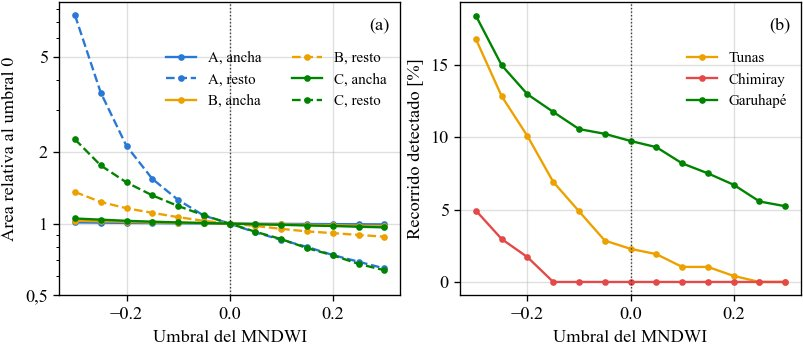

In [40]:
DELTAS = np.round(np.arange(-0.3, 0.301, 0.05), 2)
COLOR_ZONA = {"Paraná": "#2a78d6", "Uruguay–Chimiray": "#eda100", "Garuhapé": "#008300"}
COLOR_ARROYO = {"Arroyo Tunas": "#eda100", "Arroyo Chimiray": "#e34948", "Arroyo Garuhapé": "#008300"}
f = FECHAS[0]
fig, axs = plt.subplots(1, 2, figsize=(ancho(1.0), 2.9))
for z, d in ZONAS.items():
    x = IND[f][z]["MNDWI"]
    ancha = dilatar(dilatar(agua_ancha(x > 0)))
    for region, ls, rotulo in [(ancha, "-", "ancha"), (~ancha, "--", "resto")]:
        area = np.array([((x > u) & region).sum() for u in DELTAS])
        relativa = area / area[DELTAS == 0][0]
        print(f"Zona {d['letra']}, {rotulo}: área relativa entre {relativa.min():.2f} y {relativa.max():.2f}")
        axs[0].plot(DELTAS, area / area[DELTAS == 0][0], ls=ls, color=COLOR_ZONA[z], lw=1.4,
                    marker="o", ms=3, label=f"{d['letra']}, {rotulo}")
for (z, nombre) in LONGITUDINALES:
    t = mayor_tramo(f, z, nombre)
    x = IND[f][z]["MNDWI"]
    fuera = ~en_puntos(dilatar(agua_ancha(x > 0)), t)
    det = [100 * en_puntos(dilatar(x > u), t)[fuera].mean() for u in DELTAS]
    axs[1].plot(DELTAS, det, color=COLOR_ARROYO[nombre], lw=1.4, marker="o", ms=3, label=nombre.replace("Arroyo ", ""))
axs[0].set(xlabel="Umbral del MNDWI", ylabel="Área relativa al umbral 0", yscale="log")
axs[0].set_yticks([0.5, 1, 2, 5], ["0,5", "1", "2", "5"])
axs[1].set(xlabel="Umbral del MNDWI", ylabel="Recorrido detectado [%]")
for ax, letra in zip(axs, "ab"):
    ax.axvline(0, color="0.2", lw=0.8, ls=":")
    ax.grid(alpha=0.4)
    ax.text(0.97, 0.95, f"({letra})", transform=ax.transAxes, ha="right", va="top")
axs[0].legend(ncol=2, fontsize=9, loc="upper right", bbox_to_anchor=(1, 0.88), frameon=False)
axs[1].legend(fontsize=9, loc="upper right", bbox_to_anchor=(1, 0.88), frameon=False)
guardar(fig, "sensibilidad_umbral")
plt.show()

**Qué se observa.**

- **(a) Agua ancha:** su área casi no cambia con el umbral. Entre −0,3 y 0,3 varía como máximo un 5 % en las tres zonas, porque sus píxeles tienen MNDWI cercano a 1.
- **(a) El resto del agua:** varía mucho, sobre todo al bajar el umbral. Con −0,3 se multiplica por 7,5 en la zona A, por 2,3 en la C y por 1,4 en la B. En la zona A, además de píxeles mezcla, empieza a incluir zonas urbanas (la ciudad da −0,35 ± 0,07).
- **(b) Recorrido detectado de los arroyos:** también depende mucho del umbral. Entre 0,3 y −0,3, el Garuhapé pasa de 5 % a 18 % y el Tunas de 0 % a 17 %. El Chimiray recién aparece por debajo de −0,15.

El área de un río grande es una medida robusta; la de un arroyo depende de una elección arbitraria del umbral. Bajarlo para recuperar arroyos agrega falsos positivos en otras partes.

### Tamaño de los cuerpos de agua

Se cuentan los cuerpos de agua separados (componentes conexas con vecindad de 8) de la máscara del MNDWI y de la de `QA_PIXEL`, agrupados por tamaño. Un píxel son 900 m², y 9 píxeles equivalen a un cuadrado de 90 m de lado.

In [41]:
CLASES_TAMANO = [(1, 1, "1 px"), (2, 9, "2 a 9 px"), (10, 99, "10 a 99 px"), (100, 999, "100 a 999 px"),
                 (1000, np.inf, "1000 px o más")]


def contar_cuerpos(mascara):
    n, _, stats, _ = cv2.connectedComponentsWithStats(mascara.astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    return {r: int(((areas >= lo) & (areas <= hi)).sum()) for lo, hi, r in CLASES_TAMANO}


filas = []
for f in FECHAS:
    for z in ZONAS:
        q = RECORTES[f][z]["qa"]
        for fuente, m in [("MNDWI > 0", IND[f][z]["MNDWI"] > 0), ("QA_PIXEL", q["agua"])]:
            filas.append({"Zona": z, "Fecha": f, "Máscara": fuente, **contar_cuerpos(m & q["valido"])})
pd.DataFrame(filas).set_index(["Zona", "Fecha", "Máscara"]).sort_index(level=[0, 1], sort_remaining=False)

1 px  2 a 9 px  10 a 99 px  \
Zona             Fecha      Máscara                                 
Garuhapé         03/04/2024 MNDWI > 0    16        24           8   
                            QA_PIXEL     10        15           6   
                 30/06/2024 MNDWI > 0    38        33           9   
                            QA_PIXEL     56        24           7   
Paraná           03/04/2024 MNDWI > 0    14        17           7   
                            QA_PIXEL     26        19           4   
                 30/06/2024 MNDWI > 0    22        26           6   
                            QA_PIXEL     95        49           6   
Uruguay–Chimiray 03/04/2024 MNDWI > 0    14        15           2   
                            QA_PIXEL     12         9           1   
                 30/06/2024 MNDWI > 0    20        26           2   
                            QA_PIXEL     42        23           1   

                                       100 a 999 px  1000 px o más  
Zona             Fecha      Máscara                                 
Garuhapé         03/04/2024 MNDWI > 0             0              1  
                            QA_PIXEL              1              1  
                 30/06/2024 MNDWI > 0             0              1  
                            QA_PIXEL              0              1  
Paraná           03/04/2024 MNDWI > 0             1              2  
                            QA_PIXEL              0              1  
                 30/06/2024 MNDWI > 0             1              1  
                            QA_PIXEL              1              1  
Uruguay–Chimiray 03/04/2024 MNDWI > 0             0              1  
                            QA_PIXEL              0              1  
                 30/06/2024 MNDWI > 0             0              1  
                            QA_PIXEL              0              1

**Qué se observa.**

- **Cada máscara tiene uno o dos cuerpos de más de 1000 píxeles,** los ríos y el embalse, y decenas de cuerpos de 1 a 9 píxeles.
- **Los cuerpos de 10 a 99 píxeles (de 0,9 a 9 ha) son entre 2 y 9 por zona.** Son lagunas y tajamares que sí se detectan.
- **Los de un solo píxel son ambiguos:** pueden ser tajamares chicos, tramos sueltos de arroyo o ruido. `QA_PIXEL` tiene muchos más en junio (95 en la zona A, frente a 22 del MNDWI). Por debajo de unos pocos píxeles, la resolución no permite saber qué es cada uno.

### ¿Alcanza la resolución de 30 m?

**Para los ríos y los lagos sí; para la mayor parte de los arroyos no.**

- **Agua grande:** el Paraná (unos 2,2 km de ancho en su sección más angosta de la zona), el Uruguay (unos 530 m), las bahías del embalse y las lagunas de varias hectáreas se detectan completos y con bordes nítidos. Su área coincide con la de `QA_PIXEL` en menos de 0,6 km² y casi no depende del umbral.
- **Agua chica:** de los 230 a 255 km de arroyos que mapea OpenStreetMap en cada zona, el MNDWI detecta como agua menos del 4 %. Se detectan los tramos con al menos unos 90 m de agua abierta (3 píxeles), como el Garuhapé cerca de su desembocadura. Los tramos angostos solo dejan una subida del índice que no llega al umbral, porque el píxel mezcla unos pocos metros de agua con monte.
- **El monte ribereño agrava el problema:** el NDVI sobre los recorridos es de vegetación densa, así que en la mayoría de los arroyos el agua está, además, tapada. Ni con un píxel más chico se vería un cauce cubierto por la copa de los árboles.
- **Tunas y Chimiray:** el Tunas se ve mejor porque en su tramo bajo el corredor es más abierto (NDVI 0,64 en junio) y deja una señal de agua mezclada. El Chimiray corre bajo monte cerrado y solo se reconoce por la franja de vegetación que lo acompaña.

**Cómo se podría mejorar:**

- Usar imágenes de mayor resolución. Sentinel-2 tiene verde y NIR a 10 m, así que permite un NDWI a 10 m y un MNDWI a 20 m, con el SWIR 1.
- Usar la banda pancromática de 15 m del producto de nivel 1 de Landsat, que no está en el de nivel 2. Cubre solo el visible, así que no mejora el SWIR.
- Estimar la **fracción de agua** de cada píxel por desmezcla espectral, en lugar de decidir agua o no agua.
- Para los arroyos bajo monte, usar indicadores indirectos, como el corredor de vegetación ribereña, más que el agua en sí.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Referencia para arroyos | Recorridos de OpenStreetMap | Son independientes del sensor | `QA_PIXEL` | Clasifica a 30 m, con el mismo límite que los índices | — |
| Margen de detección | Vecindad de 3 × 3 píxeles | Absorbe el error de posición de los recorridos y el de la cuadrícula | Solo el píxel del recorrido | Un corrimiento de un píxel daría el arroyo por no detectado | — |
| Cauce principal | Apertura morfológica con un elemento circular de 9 px | Separa el agua de más de unos 270 m de ancho, aunque esté conectada con los arroyos | Excluir el componente conexo de cada río | La desembocadura de los arroyos forma parte del mismo componente | — |
| Composición para mirar arroyos | 2-5-7 con CLAHE | Resalta el corredor de monte de cada arroyo | Percentiles 2–98 | El estiramiento global aplana los detalles locales | Visual |
| Perfiles de los arroyos | A 3 y 8 km de la desembocadura, y a 1 km en el Garuhapé | Comparan tramos anchos y angostos del mismo arroyo y entre arroyos | — | — | — |
| Escala del gráfico de sensibilidad | Logarítmica | El resto del agua de la zona A llega a 7,5 veces y aplastaba las demás curvas | Lineal | No se veían las variaciones del agua ancha | Visual |

## 7. Comparación entre fechas

### Áreas de agua en cada fecha

Se compara la máscara del MNDWI > 0 de las dos fechas, sobre los píxeles válidos en ambas (en junio se excluyen las nubes del Paraná). Como en la sección anterior, se separa el agua ancha (la que queda después de la apertura en cualquiera de las dos fechas, con un margen de 2 píxeles) del resto. Además del área, se informa la **coincidencia en el agua entre fechas**, con la misma definición que la usada contra `QA_PIXEL`: de los píxeles que son agua en alguna de las dos fechas, porcentaje que es agua en ambas.

In [42]:
MASCARA_FECHA = {(f, z): IND[f][z]["MNDWI"] > 0 for f in FECHAS for z in ZONAS}
VALIDO_AMBAS = {z: RECORTES[FECHAS[0]][z]["qa"]["valido"] & RECORTES[FECHAS[1]][z]["qa"]["valido"] for z in ZONAS}
REGION_ANCHA = {z: dilatar(dilatar(agua_ancha(MASCARA_FECHA[FECHAS[0], z]) | agua_ancha(MASCARA_FECHA[FECHAS[1], z])))
                for z in ZONAS}


def comparar_fechas(a, j):
    return {"Abril [km²]": a.sum() * KM2_PIXEL, "Junio [km²]": j.sum() * KM2_PIXEL,
            "Cambio [%]": 100 * (j.sum() / a.sum() - 1),
            "Solo abril [km²]": (a & ~j).sum() * KM2_PIXEL, "Solo junio [km²]": (~a & j).sum() * KM2_PIXEL,
            "Coincidencia en el agua [%]": 100 * (a & j).sum() / (a | j).sum()}


filas = []
for z in ZONAS:
    for region, m in [("Agua ancha", REGION_ANCHA[z]), ("Resto", ~REGION_ANCHA[z]), ("Total", True)]:
        r = VALIDO_AMBAS[z] & m
        filas.append({"Zona": z, "Región": region,
                      **comparar_fechas(MASCARA_FECHA[FECHAS[0], z] & r, MASCARA_FECHA[FECHAS[1], z] & r)})
AREAS_FECHAS = pd.DataFrame(filas).set_index(["Zona", "Región"])
AREAS_FECHAS.round(2)

Abril [km²]  Junio [km²]  Cambio [%]  \
Zona             Región                                             
Paraná           Agua ancha       131.14       131.64        0.38   
                 Resto              0.48         0.71       47.38   
                 Total            131.62       132.34        0.55   
Uruguay–Chimiray Agua ancha        11.94        12.12        1.51   
                 Resto              0.80         0.86        7.76   
                 Total             12.74        12.99        1.91   
Garuhapé         Agua ancha         6.73         6.87        2.01   
                 Resto              0.43         0.55       29.11   
                 Total              7.16         7.42        3.62   

                             Solo abril [km²]  Solo junio [km²]  \
Zona             Región                                           
Paraná           Agua ancha              0.10              0.59   
                 Resto                   0.04              0.27   
                 Total                   0.14              0.86   
Uruguay–Chimiray Agua ancha              0.02              0.20   
                 Resto                   0.01              0.08   
                 Total                   0.03              0.28   
Garuhapé         Agua ancha              0.03              0.17   
                 Resto                   0.03              0.15   
                 Total                   0.06              0.32   

                             Coincidencia en el agua [%]  
Zona             Región                                   
Paraná           Agua ancha                        99.48  
                 Resto                             59.16  
                 Total                             99.25  
Uruguay–Chimiray Agua ancha                        98.21  
                 Resto                             89.63  
                 Total                             97.64  
Garuhapé         Agua ancha                        97.15  
                 Resto                             68.37  
                 Total                             94.92

**Qué se observa.**

- **El Paraná funciona como control:** su agua ancha cambia un 0,4 % (de 131,1 a 131,6 km²) y coincide en un 99,5 % entre fechas. Su nivel lo regula la represa de Yacyretá, así que se esperaba un área estable, y el método la reproduce. El Uruguay y el Paraná de la zona C cambian un 1,5 % y un 2,0 %.
- **El agua chica (el resto) es inestable:**
  - Cambia un 47 % en la zona A, un 8 % en la B y un 29 % en la C.
  - Coincide entre fechas en un 59 %, un 90 % y un 68 %.
  - Son áreas muy chicas (0,4 a 0,9 km²), formadas sobre todo por píxeles mezcla.
- **En las tres zonas hay más agua en junio:** lo que aparece solo en junio supera ampliamente a lo que aparece solo en abril (0,86 frente a 0,14 km² en la zona A).

In [43]:
# Ancho medio de los ríos de las zonas B y C: área del agua ancha dividida por el largo de su eje (OSM)
filas = []
for z, rio in [("Uruguay–Chimiray", "Río Uruguay"), ("Garuhapé", "Río Paraná")]:
    for f in FECHAS:
        largo_m = sum(len(t["puntos"]) for t in RECORRIDOS[f, z].values() if t["nombre"] == rio) * 0.5 * 30
        area_m2 = (agua_ancha(MASCARA_FECHA[f, z]) & VALIDO_AMBAS[z]).sum() * 900
        filas.append({"Río": f"{rio} (zona {ZONAS[z]['letra']})", "Fecha": f, "Largo del eje [km]": largo_m / 1000,
                      "Ancho medio [m]": area_m2 / largo_m})
pd.DataFrame(filas).pivot_table(index="Río", columns="Fecha", values="Ancho medio [m]").round(1)

Fecha,03/04/2024,30/06/2024
Río,,
Río Paraná (zona C),439.2,448.3
Río Uruguay (zona B),471.5,483.2


**Qué se observa.** El ancho medio del Uruguay pasa de 471,5 a 483,2 m, y el del Paraná en la zona C de 439,2 a 448,3 m. El aumento es de 9 a 12 m, menos de medio píxel, y del mismo orden que la franja de píxeles mezcla de cada orilla.

### Mapa de cambio

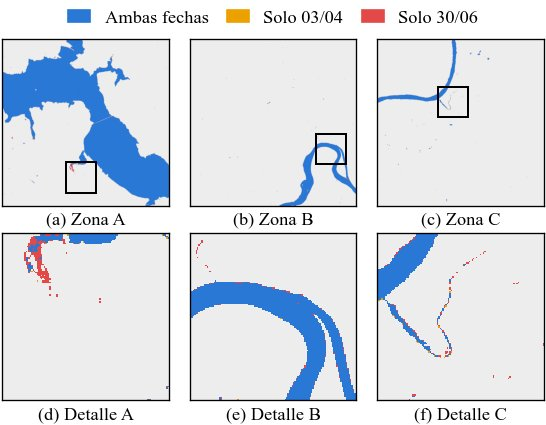

In [44]:
CATEGORIAS_CAMBIO = {"Ambas fechas": "#2a78d6", f"Solo {FECHAS[0][:5]}": "#eda100", f"Solo {FECHAS[1][:5]}": "#e34948"}


def imagen_cambio(z, mascara_junio=None):
    a = MASCARA_FECHA[FECHAS[0], z] & VALIDO_AMBAS[z]
    j = (MASCARA_FECHA[FECHAS[1], z] if mascara_junio is None else mascara_junio) & VALIDO_AMBAS[z]
    img = np.tile(FONDO, (*a.shape, 1))
    for cat, m in zip(CATEGORIAS_CAMBIO, [a & j, a & ~j, ~a & j]):
        img[m] = matplotlib.colors.to_rgb(CATEGORIAS_CAMBIO[cat])
    return img, a ^ j


fig, axs = plt.subplots(2, len(ZONAS), figsize=(ancho(0.7), 3.6))
for j, (z, d) in enumerate(ZONAS.items()):
    img, cambio = imagen_cambio(z)
    v = ventana_detalle(cambio & ~REGION_ANCHA[z])   # el detalle muestra el agua chica
    axs[0, j].imshow(img)
    axs[0, j].add_patch(Rectangle((v[1].start - 0.5, v[0].start - 0.5), LADO_DETALLE, LADO_DETALLE,
                                  fill=False, ec="black", lw=1.2))
    axs[1, j].imshow(img[v], interpolation="nearest")
    axs[0, j].set_xlabel(f"({'abc'[j]}) Zona {d['letra']}")
    axs[1, j].set_xlabel(f"({'def'[j]}) Detalle {d['letra']}")
    for ax in axs[:, j]:
        ax.set_xticks([])
        ax.set_yticks([])
fig.get_layout_engine().set(rect=(0, 0, 1, 0.91))
fig.legend([Rectangle((0, 0), 1, 1, color=c) for c in CATEGORIAS_CAMBIO.values()], CATEGORIAS_CAMBIO,
           loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
           handlelength=1.2, columnspacing=1.0)
guardar(fig, "cambios_fechas")
plt.show()

**Qué se observa.** A escala de zona, las dos fechas coinciden casi por completo. Los cambios forman líneas de uno o dos píxeles en las orillas y se concentran en el agua chica:

- **Zona A:** un arroyo que desemboca en una bahía del embalse tiene mucha más agua en junio (rojo).
- **Zona B:** el borde del Uruguay suma píxeles en junio.
- **Zona C:** el tramo bajo del arroyo Garuhapé alterna píxeles que son agua solo en una u otra fecha. Es un cauce de 2 a 3 píxeles de ancho, donde cada píxel mezcla queda cerca del umbral.

### Dónde están los cambios y cuánto explica el corrimiento

En la sección 2, la correlación de fase sobre el NIR estimó un corrimiento de unos 0,45 píxeles por eje entre las escenas, que se decidió no corregir. Un corrimiento así desplaza los bordes del agua y puede marcar como cambio una franja de un píxel en todas las orillas. Se verifica de dos formas:

- **Ubicación de los cambios:** qué parte de los píxeles que cambian cae en la franja de la orilla (a un píxel o menos del borde del agua en alguna de las dos fechas).
- **Prueba directa sobre las máscaras:** se desplaza una fecha respecto de la otra en pasos de 1/4 de píxel y se busca el desplazamiento con menos cambios. Las dos fechas se interpolan por igual (abril se mueve −d/2 y junio +d/2), para que el suavizado de la interpolación no favorezca a ninguna.

In [45]:
filas = []
for z in ZONAS:
    a, j = MASCARA_FECHA[FECHAS[0], z], MASCARA_FECHA[FECHAS[1], z]
    orilla = (dilatar(a) & dilatar(~a)) | (dilatar(j) & dilatar(~j))
    for region, m in [("Agua ancha", REGION_ANCHA[z]), ("Resto", ~REGION_ANCHA[z])]:
        cambio = (a ^ j) & VALIDO_AMBAS[z] & m
        filas.append({"Zona": z, "Región": region, "Píxeles que cambian": cambio.sum(),
                      "En la orilla [%]": 100 * (cambio & orilla).sum() / max(cambio.sum(), 1)})
pd.DataFrame(filas).set_index(["Zona", "Región"]).round(1)

Píxeles que cambian  En la orilla [%]
Zona             Región                                           
Paraná           Agua ancha                  767              98.4
                 Resto                       339              95.3
Uruguay–Chimiray Agua ancha                  241             100.0
                 Resto                       101             100.0
Garuhapé         Agua ancha                  218             100.0
                 Resto                       204             100.0

In [46]:
def trasladar(img, dx, dy):
    return cv2.warpAffine(img, np.float32([[1, 0, dx], [0, 1, dy]]), img.shape[::-1],
                          flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


PASOS = np.round(np.arange(-0.75, 0.76, 0.25), 2)
filas = []
for z in ZONAS:
    a_ind, j_ind = (np.nan_to_num(IND[f][z]["MNDWI"], nan=-1).astype(np.float32) for f in FECHAS)
    cuenta = {}
    for dy in PASOS:
        for dx in PASOS:
            cambio = (trasladar(a_ind, -dx / 2, -dy / 2) > 0) ^ (trasladar(j_ind, dx / 2, dy / 2) > 0)
            cuenta[dx, dy] = (cambio & VALIDO_AMBAS[z])[5:-5, 5:-5].sum()   # sin los bordes del recorte
    mejor = min(cuenta, key=cuenta.get)
    filas.append({"Zona": z, "Cambios sin desplazar": cuenta[0.0, 0.0],
                  "Desplazamiento con menos cambios [col, fil]": f"{mejor[0]:+.2f}, {mejor[1]:+.2f}",
                  "Cambios con ese desplazamiento": cuenta[mejor],
                  "Reducción [%]": 100 * (1 - cuenta[mejor] / cuenta[0.0, 0.0])})
pd.DataFrame(filas).set_index("Zona").round(1)

,Cambios sin desplazar,"Desplazamiento con menos cambios [col, fil]",Cambios con ese desplazamiento,Reducción [%]
Zona,,,,
Paraná,1085,"+0.00, +0.25",1016,6.4
Uruguay–Chimiray,330,"+0.00, +0.25",292,11.5
Garuhapé,419,"+0.00, +0.25",348,16.9


**Qué se observa.**

- **Entre el 95 % y el 100 % de los cambios están en la orilla.** Los píxeles que aparecen solo en junio en las zonas con relieve también están junto al agua, así que no hay indicios de sombras confundidas con agua.
- **El corrimiento de 0,45 píxeles que estimó la correlación de fase no se confirma en los bordes del agua.** El desplazamiento con menos cambios es de 0 columnas y 0,25 filas en las tres zonas, y los reduce solo entre un 6 % y un 17 %. La correlación de fase se calculó sobre toda la textura del NIR, no sobre las orillas. La decisión de no remuestrear se mantiene.

### Interpretación de los cambios

La consigna pide considerar los factores externos antes de concluir. Entre abril y junio hay varios, además de un posible cambio real del agua:

- **Radiometría del agua:** en junio el agua tiene MNDWI más alto (1,00 frente a 0,94 en el Paraná), porque su SWIR 1 queda en 0 con más frecuencia (el 56 % de los píxeles de agua daba negativo, contra el 0,6 % en abril) y porque el Paraná se ve más verde. Un píxel mezcla de la orilla tiene entonces más probabilidad de superar el umbral en junio. Eso agranda el agua sin que cambie el nivel, y explicaría una expansión pareja en todas las orillas, como la observada.
- **Satélites distintos:** Landsat 9 en abril y Landsat 8 en junio. Están calibrados entre sí, pero la corrección atmosférica de cada escena puede diferir un poco.
- **Sol más bajo en junio** (30,6° frente a 44,8°): las sombras son 1,7 veces más largas, pero los cambios están en la orilla y no en las laderas, así que este factor no aparece en los resultados.
- **Vegetación en invierno:** el NDVI sobre los arroyos baja en junio. Con menos follaje en el monte ribereño se ve más agua mezclada, lo que coincide con la mayor detección de arroyos de la sección anterior.
- **Nivel de los ríos y lluvias:** no se cuenta con datos de altura de los ríos ni de precipitación de esas fechas. Sin ellos no se puede atribuir el aumento de agua a un cambio hidrológico.

**Conclusión.** Con dos fechas y sin datos hidrológicos, lo único robusto es que **los cuerpos de agua grandes se mantuvieron estables**: el Paraná, regulado, cambió un 0,4 %; el Uruguay y el Paraná de la zona C, entre 1,5 % y 2 %, menos de medio píxel de ancho. Las diferencias en el agua chica están dentro de la incertidumbre del método (píxeles mezcla, radiometría distinta entre escenas) y no se pueden interpretar como cambios reales. Para detectar cambios en arroyos y tajamares haría falta una serie de imágenes y datos de campo.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Píxeles comparados | Válidos en las dos fechas | Las nubes de junio en el Paraná no deben contar como cambio | Todos los píxeles | Una nube o su sombra aparecería como agua perdida o ganada | — |
| Regiones | Agua ancha (apertura en cualquiera de las fechas, con 2 px de margen) y resto | Separa el cambio de los ríos del del agua chica | Solo el total | El área de los ríos tapa los cambios del agua chica | Métrica |
| Medida de estabilidad | Coincidencia en el agua entre fechas | Misma definición que contra `QA_PIXEL`; no se infla con la tierra | Diferencia de áreas sola | Dos máscaras con igual área pueden no superponerse | — |
| Ancho de los ríos | Área del agua ancha dividida por el largo del eje de OSM | Resume el cambio de todo el tramo en un número | Perfiles transversales | Un perfil depende del punto elegido | — |
| Corrimiento entre fechas | Sin remuestreo (se mantiene) | El desplazamiento con menos cambios es de 0,25 filas y los reduce solo entre 6 % y 17 % | Corregir los 0,45 px de la correlación de fase | Corregirlo aumentaba los cambios; no se confirma en los bordes del agua | Métrica |
| Prueba del corrimiento | Interpolar las dos fechas por igual | Si solo se interpola junio, el suavizado agrega cambios por sí mismo | Trasladar solo junio | Daba más del doble de cambios con cualquier desplazamiento | Métrica |

## 8. Cambios en lagunas y represas

Las zonas A, B y C se eligieron para comparar agua grande y chica, no para ver cambios, y entre fechas resultaron casi estables. Para analizar un cambio real se buscan en toda la escena los lugares donde el agua más cambió entre abril y junio, y se estudian dos:

- **Zona D, San Carlos (Corrientes):** un grupo de lagunas y represas.
- **Zona E, bahía del arroyo Garupá (Misiones):** un brazo del embalse de Yacyretá, cuyo nivel está regulado.

### Búsqueda en toda la escena

Se calcula la máscara del MNDWI > 0 de toda la escena en las dos fechas, en la cuadrícula del 03/04 (la de junio se corre 50 columnas). Para que no cuenten las líneas de un píxel de las orillas, a los píxeles que ganan o pierden agua se les aplica una apertura morfológica de 3 × 3: quedan solo los cambios de más de un píxel de ancho. Después se suma el cambio en ventanas de 10 km y se listan los máximos separados entre sí.

In [47]:
def a_cuadricula_ref(x, e):
    # Traslada una banda completa de la escena e a la cuadrícula de la escena de referencia (03/04)
    dc = int(round((e["x0"] - REF["x0"]) / e["celda"]))
    df = int(round((REF["y0"] - e["y0"]) / e["celda"]))
    y = np.zeros_like(x)
    h, w = x.shape
    y[max(df, 0):h + min(df, 0), max(dc, 0):w + min(dc, 0)] = x[max(-df, 0):h - max(df, 0), max(-dc, 0):w - max(dc, 0)]
    return y


def utm_a_latlon(x, y, huso=21):
    # UTM (sin falso norte) a geográficas, fórmulas inversas de Snyder (1987)
    a, f, k0 = 6378137.0, 1 / 298.257223563, 0.9996
    e2 = f * (2 - f)
    ep2 = e2 / (1 - e2)
    e1 = (1 - math.sqrt(1 - e2)) / (1 + math.sqrt(1 - e2))
    mu = y / k0 / (a * (1 - e2 / 4 - 3 * e2**2 / 64 - 5 * e2**3 / 256))
    p1 = (mu + (3 * e1 / 2 - 27 * e1**3 / 32) * math.sin(2 * mu) + (21 * e1**2 / 16 - 55 * e1**4 / 32) * math.sin(4 * mu)
          + (151 * e1**3 / 96) * math.sin(6 * mu))
    N1 = a / math.sqrt(1 - e2 * math.sin(p1) ** 2)
    T1, C1 = math.tan(p1) ** 2, ep2 * math.cos(p1) ** 2
    R1 = a * (1 - e2) / (1 - e2 * math.sin(p1) ** 2) ** 1.5
    D = (x - 500000) / (N1 * k0)
    lat = p1 - (N1 * math.tan(p1) / R1) * (D**2 / 2 - (5 + 3 * T1 + 10 * C1 - 4 * C1**2 - 9 * ep2) * D**4 / 24)
    lon = (D - (1 + 2 * T1 + C1) * D**3 / 6) / math.cos(p1)
    return math.degrees(lat), 6 * huso - 183 + math.degrees(lon)


agua_escena, valido_escena = {}, None
for f, e in ESCENAS.items():
    verde, swir = (a_cuadricula_ref(np.clip(a_reflectancia(leer_tif(e, f"SR_B{b}"), e, b), 0, 1), e) for b in (3, 6))
    with np.errstate(invalid="ignore", divide="ignore"):
        agua_escena[f] = (verde - swir) / (verde + swir) > 0
    q = mascaras_qa(a_cuadricula_ref(leer_tif(e, "QA_PIXEL"), e))
    ok = q["valido"] & np.isfinite(verde) & np.isfinite(swir) & (verde + swir > 0)
    valido_escena = ok if valido_escena is None else valido_escena & ok
del verde, swir, q, ok

a, j = agua_escena[FECHAS[0]] & valido_escena, agua_escena[FECHAS[1]] & valido_escena
gana = cv2.morphologyEx((j & ~a).astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
pierde = cv2.morphologyEx((a & ~j).astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
print(f"Agua en toda la escena: {a.sum() * KM2_PIXEL:.1f} km² el {FECHAS[0]} y {j.sum() * KM2_PIXEL:.1f} km² el {FECHAS[1]}")
print(f"Cambios de más de un píxel de ancho: gana {gana.sum() * KM2_PIXEL:.2f} km², pierde {pierde.sum() * KM2_PIXEL:.2f} km²")

lado = 333   # ventanas de 10 km
suma = cv2.boxFilter((gana | pierde).astype(np.float32), -1, (lado, lado), normalize=False)
suma[~valido_escena] = 0
filas = []
for k in range(6):
    fi, co = np.unravel_index(np.argmax(suma), suma.shape)
    lat, lon = utm_a_latlon(REF["x0"] + REF["celda"] * co, REF["y0"] - REF["celda"] * fi)
    en_ventana = np.s_[max(fi - lado // 2, 0):fi + lado // 2, max(co - lado // 2, 0):co + lado // 2]
    filas.append({"Candidato": k + 1, "Latitud": round(lat, 3), "Longitud": round(lon, 3),
                  "Gana [ha]": gana[en_ventana].sum() * 0.09, "Pierde [ha]": pierde[en_ventana].sum() * 0.09})
    suma[max(fi - lado, 0):fi + lado, max(co - lado, 0):co + lado] = 0
del agua_escena, valido_escena, a, j, gana, pierde, suma
pd.DataFrame(filas).set_index("Candidato").round(1)

Agua en toda la escena: 989.9 km² el 03/04/2024 y 1010.8 km² el 30/06/2024
Cambios de más de un píxel de ancho: gana 1.86 km², pierde 0.16 km²


,Latitud,Longitud,Gana [ha],Pierde [ha]
Candidato,,,,
1,-27.7,-56.0,69.8,0.0
2,-27.9,-56.1,32.0,0.0
3,-28.1,-55.6,13.6,0.0
4,-27.5,-55.8,11.2,1.1
5,-27.1,-56.2,12.3,0.0
6,-27.4,-56.0,9.1,0.0


**Qué se observa.** En toda la escena el agua pasa de unos 990 a unos 1011 km² (+2 %), y los cambios de más de un píxel de ancho suman menos de 2 km². No aparece ninguna crecida extensa. El mayor foco está en San Carlos (Corrientes), con varias lagunas que crecieron. Le siguen una represa aislada en el oeste de Corrientes, la orilla del Uruguay en la zona B y la bahía del arroyo Garupá, al sur de Posadas.

Se eligen el primero (zona D) y la bahía del Garupá (zona E) para contrastar dos tipos de cuerpo de agua: un grupo de lagunas y represas que pueden llenarse o vaciarse, y un brazo del embalse de Yacyretá, cuyo nivel está regulado. La represa del oeste de Corrientes no se analiza aparte porque es un caso como los de la zona D.

### Zonas D y E

In [48]:
ZONAS_CAMBIO = {
    "San Carlos": {"lat": -27.685, "lon": -56.015, "lado": 20, "letra": "D",
                   "descripcion": "Lagunas y represas de San Carlos (departamento Ituzaingó, Corrientes)"},
    "Bahía del Garupá": {"lat": -27.504, "lon": -55.832, "lado": 10, "letra": "E",
                         "descripcion": "Bahía del arroyo Garupá en el embalse de Yacyretá (Garupá, Misiones)"},
}
RECORTES_CAMBIO = {f: cargar_zonas(e, ZONAS_CAMBIO) for f, e in ESCENAS.items()}
for recortes in RECORTES_CAMBIO.values():
    for r in recortes.values():
        np.clip(r["refl"], 0, 1, out=r["refl"])

AGUA_CAMBIO = {(f, z): dif_normalizada(RECORTES_CAMBIO[f][z]["refl"], 3, 6) > 0 for f in FECHAS for z in ZONAS_CAMBIO}
VALIDO_CAMBIO = {z: RECORTES_CAMBIO[FECHAS[0]][z]["qa"]["valido"] & RECORTES_CAMBIO[FECHAS[1]][z]["qa"]["valido"]
                 for z in ZONAS_CAMBIO}
pd.DataFrame([{"Zona": z, "Inválidos [%]": 100 * (~VALIDO_CAMBIO[z]).mean(),
               **comparar_fechas(AGUA_CAMBIO[FECHAS[0], z] & VALIDO_CAMBIO[z], AGUA_CAMBIO[FECHAS[1], z] & VALIDO_CAMBIO[z])}
              for z in ZONAS_CAMBIO]).set_index("Zona").round(2)

,Inválidos [%],Abril [km²],Junio [km²],Cambio [%],Solo abril [km²],Solo junio [km²],Coincidencia en el agua [%]
Zona,,,,,,,
San Carlos,0.00,3.36,4.54,35.30,0.01,1.20,73.46
Bahía del Garupá,0.23,13.84,14.57,5.29,0.11,0.84,93.49


**Qué se observa.**

- **En San Carlos el agua pasa de 3,36 a 4,54 km² (+35 %)** y la coincidencia entre fechas es de solo 73 %: casi todo el cambio es agua nueva en junio (1,20 km²) y prácticamente no se pierde agua.
- **En la bahía del Garupá el cambio es mucho menor (+5,3 %),** con 93,5 % de coincidencia.
- **Las dos zonas casi no tienen píxeles inválidos.**

### Crecimiento de cada cuerpo de agua

En la sección 7 se vio que en junio los píxeles de orilla tienden a dar agua con más facilidad, por una diferencia de radiometría entre las escenas. Si eso fuera todo, cada laguna crecería un anillo parejo de menos de un píxel. Para distinguir ese efecto de un llenado real, se mide para cada cuerpo de agua (componentes conexas de la unión de las dos fechas, de 20 píxeles o más):

- **Crecimiento medio del borde:** el área ganada dividida por el perímetro de abril, en píxeles. Indica cuánto avanzó la orilla en promedio.
- **Distancia de lo nuevo:** el percentil 90 de la distancia de los píxeles nuevos a la orilla de abril. Un anillo parejo da 1 píxel o menos; un llenado de la parte poco profunda da varios píxeles en un solo sector.
- **NDVI en abril de lo nuevo:** qué había antes donde ahora hay agua. Valores altos indican vegetación (pasto o plantas acuáticas); valores bajos, suelo húmedo o barro.

Como **control** se calculan las mismas medidas para el agua ancha de las zonas A, B y C (el Paraná y el Uruguay), que casi no cambió.

In [49]:
def medir_cuerpos(agua_a, agua_j, valido, refl_abril, minimo=20):
    a, j = agua_a & valido, agua_j & valido
    n, etiquetas, stats, centros = cv2.connectedComponentsWithStats((a | j).astype(np.uint8), connectivity=8)
    distancia = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)   # px hasta el agua de abril
    ndvi = dif_normalizada(refl_abril, 5, 4)
    filas = []
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] < minimo:
            continue
        cuerpo = etiquetas == k
        ca, cj = cuerpo & a, cuerpo & j
        nuevos = cj & ~ca
        perimetro = (ca & dilatar(~ca)).sum()
        filas.append({"Fila": int(centros[k][1]), "Col": int(centros[k][0]),
                      "Abril [ha]": ca.sum() * 0.09, "Junio [ha]": cj.sum() * 0.09,
                      "Cambio [%]": 100 * (cj.sum() / ca.sum() - 1) if ca.sum() else np.inf,
                      "Crecimiento medio del borde [px]": (cj.sum() - ca.sum()) / max(perimetro, 1),
                      "Distancia p90 de lo nuevo [px]": np.percentile(distancia[nuevos], 90) if nuevos.any() else 0.0,
                      "NDVI en abril de lo nuevo": np.nanmedian(ndvi[nuevos]) if nuevos.any() else np.nan})
    return pd.DataFrame(filas).sort_values("Abril [ha]", ascending=False).reset_index(drop=True)


CUERPOS = {z: medir_cuerpos(AGUA_CAMBIO[FECHAS[0], z], AGUA_CAMBIO[FECHAS[1], z], VALIDO_CAMBIO[z],
                            RECORTES_CAMBIO[FECHAS[0]][z]["refl"]) for z in ZONAS_CAMBIO}
CUERPOS["San Carlos"].index += 1
CUERPOS["San Carlos"].round(2)

,Fila,Col,Abril [ha],Junio [ha],Cambio [%],Crecimiento medio del borde [px],Distancia p90 de lo nuevo [px],NDVI en abril de lo nuevo
1,216,198,83.79,99.63,18.90,1.09,3.28,0.36
2,384,469,83.25,98.19,17.95,0.99,2.86,0.66
3,277,356,59.13,91.89,55.40,2.60,6.14,0.58
4,486,431,33.03,46.98,42.23,1.58,3.99,0.61
5,299,339,31.05,37.35,20.29,0.76,1.91,0.70
6,642,197,18.45,21.15,14.63,0.39,0.96,0.46
7,282,427,15.66,43.29,176.44,5.48,9.22,0.61
8,49,192,1.71,2.88,68.42,0.68,0.96,0.50


In [50]:
CUERPOS["Bahía del Garupá"].head(3).round(2)

,Fila,Col,Abril [ha],Junio [ha],Cambio [%],Crecimiento medio del borde [px],Distancia p90 de lo nuevo [px],NDVI en abril de lo nuevo
0,111,234,1119.33,1135.08,1.41,0.14,4.74,0.64
1,260,244,249.57,288.54,15.61,0.49,2.74,0.75
2,325,203,6.57,17.55,167.12,1.85,2.32,0.72


In [51]:
# Control: el mismo cálculo sobre el agua ancha de las zonas A, B y C (el cuerpo más grande de cada una)
control = []
for z, d in ZONAS.items():
    a_ancha, j_ancha = (agua_ancha(MASCARA_FECHA[f, z]) for f in FECHAS)
    t = medir_cuerpos(a_ancha, j_ancha, VALIDO_AMBAS[z], RECORTES[FECHAS[0]][z]["refl"]).iloc[0]
    control.append({"Zona": f"{d['letra']}. {z}", **t.drop(["Fila", "Col"]).to_dict()})
pd.DataFrame(control).set_index("Zona").round(2)

,Abril [ha],Junio [ha],Cambio [%],Crecimiento medio del borde [px],Distancia p90 de lo nuevo [px],NDVI en abril de lo nuevo
Zona,,,,,,
A. Paraná,12887.64,12938.13,0.39,0.13,1.91,0.16
B. Uruguay–Chimiray,1171.98,1201.05,2.48,0.19,7.85,0.26
C. Garuhapé,668.70,682.47,2.06,0.13,0.95,0.41


**Qué se observa.**

- **Control:** en los ríos de las zonas A, B y C, el borde avanza en promedio entre 0,13 y 0,19 píxeles (4 a 6 m). Ese es el tamaño del efecto de borde entre las dos escenas. El percentil 90 de la distancia varía más (de 1 a 7,9 píxeles), porque unos pocos píxeles nuevos alejados de la orilla de abril, por ejemplo en islas o bancos, dominan la cola de la distribución. Por eso la medida de referencia es el crecimiento medio del borde.
- **Zona D:** los ocho cuerpos de agua crecieron, con un crecimiento medio del borde de entre 0,4 y 5,5 píxeles, es decir, de 2 a 40 veces el del control.
  - En los cuerpos 3, 4 y 7 la orilla avanzó entre 1,6 y 5,5 píxeles, con píxeles nuevos a 4 a 9 píxeles (120 a 280 m) de la orilla de abril. El agua avanzó sobre un sector: se llenó la parte poco profunda. El cuerpo 7 casi triplicó su superficie (de 15,7 a 43,3 ha).
  - Los cuerpos 1 y 2 avanzaron alrededor de un píxel; los 5, 6 y 8, menos de 0,8 píxeles, pero igual entre 2 y 5 veces el control.
  - Donde ahora hay agua, en abril había vegetación (NDVI de 0,36 a 0,70): se inundaron pasturas o la vegetación de las orillas.
- **Zona E:** el cuerpo principal de la bahía creció un 1,4 %, con 0,14 píxeles de borde, igual que el control: el nivel del embalse regulado se mantuvo. El cambio está en la cola, donde entra el arroyo. Allí los cuerpos 1 y 2 de la tabla crecieron un 16 % y casi se triplicaron, sobre lo que en abril era vegetación (NDVI 0,72 a 0,75). En la composición se ve: en abril la cola tiene manchas de vegetación dentro de la bahía (naranja en la 5-6-4) que en junio se reducen.

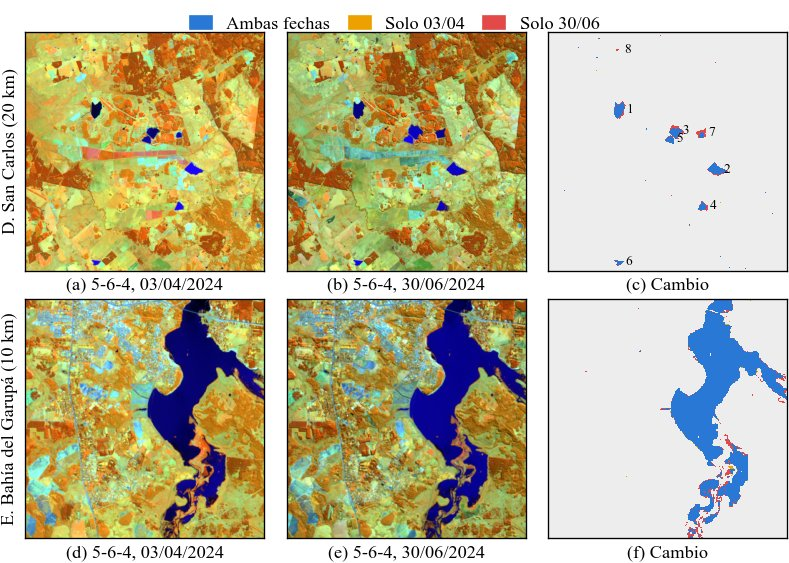

In [52]:
# Composición 5-6-4 (la recomendada en la sección 4) de las dos fechas y mapa de cambio
fig, axs = plt.subplots(len(ZONAS_CAMBIO), 3, figsize=(ancho(1.0), 4.75))
for i, (z, d) in enumerate(ZONAS_CAMBIO.items()):
    for k, f in enumerate(FECHAS):
        refl = RECORTES_CAMBIO[f][z]["refl"]
        rgb = np.dstack([estirar(refl[..., b - 1], LIM_PERC[b]) for b in (5, 6, 4)])
        mostrar_img(axs[i, k], rgb, f"5-6-4, {f}", "abcdef"[3 * i + k])
    a, j = (AGUA_CAMBIO[f, z] & VALIDO_CAMBIO[z] for f in FECHAS)
    img = np.tile(FONDO, (*a.shape, 1))
    for cat, m in zip(CATEGORIAS_CAMBIO, [a & j, a & ~j, ~a & j]):
        img[m] = matplotlib.colors.to_rgb(CATEGORIAS_CAMBIO[cat])
    mostrar_img(axs[i, 2], img, "Cambio", "abcdef"[3 * i + 2], interpolation="nearest")
    if z == "San Carlos":
        for n, cuerpo in CUERPOS[z].iterrows():
            axs[i, 2].text(cuerpo["Col"] + 18, cuerpo["Fila"], str(n), fontsize=8, va="center")
    axs[i, 0].set_ylabel(f"{d['letra']}. {z} ({d['lado']} km)")
fig.legend([Rectangle((0, 0), 1, 1, color=c) for c in CATEGORIAS_CAMBIO.values()], CATEGORIAS_CAMBIO,
           loc="outside upper center", ncol=3, frameon=False,
           handlelength=1.2, columnspacing=1.0)
guardar(fig, "cambios_lagunas")
plt.show()

### Interpretación

- **Zona D: un llenado real, que la resolución de 30 m permite medir.** Las lagunas y represas de decenas de hectáreas crecieron mucho más que el efecto de borde entre escenas, y de un solo lado, como se llena la parte poco profunda de un embalse.
  - La forma de varias de ellas, con bordes rectos, sugiere represas, posiblemente para riego, que se llenan en otoño e invierno. OpenStreetMap las registra solo como "agua", así que su uso no se puede confirmar con estos datos.
  - Tampoco se sabe si se llenaron por lluvia o por bombeo.
- **Zona E: el embalse regulado se mantuvo estable;** el cambio está en la cola de la bahía y sobre vegetación. Hay dos explicaciones posibles, que con dos fechas no se pueden separar:
  - un mayor caudal del arroyo Garupá, que inundó las márgenes vegetadas;
  - menos vegetación flotante o emergente en invierno, que deja ver el agua que antes tapaba.

**Contraste con las secciones anteriores.** Los ríos grandes y el embalse regulado cambiaron menos de un cuarto de píxel de borde. Las represas de la zona D cambiaron entre 2 y 40 veces más. Con 30 m de resolución, los cambios en cuerpos de agua de decenas de hectáreas se pueden detectar y medir; en los arroyos, en cambio, la detección misma ya es incierta.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Zona para analizar cambios | Búsqueda en toda la escena: cambios de más de un píxel de ancho (apertura de 3 × 3) sumados en ventanas de 10 km | Criterio objetivo, que descarta las líneas de orilla | El puente del arroyo Piray | Queda fuera de la escena | Métrica |
| Zonas elegidas | D (San Carlos) y E (bahía del Garupá) | El mayor foco de cambio, y el contraste entre represas y un brazo de embalse regulado | La represa del oeste de Corrientes (candidato 2) | Es un caso como los de la zona D | — |
| Tamaño de la zona E | 10 km | Encuadra la bahía | 20 km | Entraría buena parte del embalse principal y de la zona A | Visual |
| Llenado o efecto de borde | Crecimiento medio del borde y distancia de lo nuevo, con los ríos de A, B y C como control | El control mide el efecto de borde entre escenas (0,13 a 0,19 px) | Solo el cambio de área en porcentaje | En un cuerpo chico, un anillo de 1 px ya es un porcentaje grande | Métrica |
| Composición de la figura | 5-6-4 con percentiles comunes | Es la recomendada en la sección 4 y mantiene los colores del resto | Color natural | Menos contraste entre agua y tierra (ΔE, sección 4) | Métrica |